# Café Data Analysis
On this notebook we will be analysing the data collected by a Café over a period of a year.


## Table of Contents
- [Part 1 - EDA](#part-1)
  - [Step 1 - Setup](#step-1)
    - [Step 1.1 - Libraries and modules](#step-1-1)
  - [Step 2 - Basic Inspection](#step-2)
    - [Step 2.1 - Loading the data](#step-2-1)
    - [Step 2.2 - Dataset size](#step-2-2)
    - [Step 2.3 - Column types](#step-2-3)
    - [Step 2.4 - Unique values](#step-2-4)
    - [Step 2.5 - Summary statistics](#step-2-5)
  - [Step 3 - Data Cleaning and Preparation](#step-3)
    - [Step 3.1 - Missing values](#step-3-1)
    - [Step 3.2 - Text formatting and type conversion](#step-3-2)
    - [Step 3.3 - Duplicate detection](#step-3-3)
    - [Step 3.4 - Fixing item names](#step-3-4)
    - [Step 3.5 - Fixing categories](#step-3-5)
    - [Step 3.6 - Aggregating by order](#step-3-6)
    - [Step 3.7 - Data limitations](#step-3-7)
  - [Step 4 - Descriptive Statistics](#step-4)
    - [Step 4.1 - Headline figures](#step-4-1)
    - [Step 4.2 - Measures of center and spread](#step-4-2)
    - [Step 4.3 - Distribution shapes](#step-4-3)
    - [Step 4.4 - Most sold products](#step-4-4)
    - [Step 4.5 - Most sold categories](#step-4-5)
    - [Step 4.6 - The top 3 categories](#step-4-6)
    - [Step 4.7 - Top products in the top 3 categories](#step-4-7)
  - [Step 5 - Time Series Analysis and Sales Trend Investigation](#step-5)
    - [Step 5.1 - Trend isolation](#step-5-1)
    - [Step 5.2 - Structural decomposition](#step-5-2)
    - [Step 5.3 - Seasonality and recurring cycles](#step-5-3)
    - [Step 5.4 - Detrending and stationarity](#step-5-4)
    - [Step 5.5 - Key takeaways](#step-5-5)
  - [Step 6 - Category Performance and Relationship Discovery](#step-6)
    - [Step 6.1 - Category performance](#step-6-1)
    - [Step 6.2 - Concentration of sales (Pareto)](#step-6-2)
    - [Step 6.3 - Category mix through the day and the week](#step-6-3)
    - [Step 6.4 - Most sold products per month and season](#step-6-4)
    - [Step 6.5 - Relationships](#step-6-5)
    - [Step 6.6 - Anomalies](#step-6-6)
    - [Step 6.7 - Key takeaways](#step-6-7)
  - [Step 7 - Offensive Data Preparation & Feature Engineering](#step-7)
    - [Step 7.1 - Promotion and base product](#step-7-1)
    - [Step 7.2 - Time, drink and bill features](#step-7-2)
    - [Step 7.3 - Order-level features](#step-7-3)
    - [Step 7.4 - Saving the cleaned data](#step-7-4)
- [Part 2 - Market Basket Analysis](#part-2)
  - [Step 1 - Dataset Selection and Feature Engineering for MBA](#p2-step-1)
  - [Step 2 - Algorithm Selection and Metrics](#p2-step-2)
  - [Step 3 - Threshold Calibration and Overall Rules](#p2-step-3)
  - [Step 4 - Combo Deals per Daypart](#p2-step-4)
  - [Step 5 - Exporting the rules](#p2-step-5)
  - [Step 6 - Recommendations and Limitations](#p2-step-6)
- [Part 3 - Do Red Bull Promotions Increase Revenue?](#part-3)
  - [Step 1 - Daily Red Bull dataset](#p3-step-1)
  - [Step 2 - Key operational findings](#p3-step-2)
  - [Step 3 - Simple linear regression](#p3-step-3)
  - [Step 4 - Multiple linear regression](#p3-step-4)
  - [Step 5 - Sensitivity check: without the year-end spike](#p3-step-5)
  - [Step 6 - Conclusions and limitations](#p3-step-6)


<a id="part-1"></a>
## Part 1 - EDA

Note: Claude Code was used in this project

<a id="step-1"></a>
### Step 1 - Setup
Our task is to explore the data, identify interesting patterns and develop insights to help the business improve its performance.

<a id="step-1-1"></a>
#### Step 1.1 - Libraries and modules
The calculations for each step live in separate Python files in the `scripts/` folder (`cleaning.py`, `descriptive.py`, `time_series.py`, `categories.py`, `features.py`), so this notebook only shows the results and what they mean. The libraries (pandas, matplotlib, seaborn, ...) are imported inside those files, and `plot_style.py` sets the same look for every plot. The raw and cleaned data are in `data/` and the files we export (e.g. the market basket rules) go to `outputs/`. The light gray grid is on by default and kept for bar charts and scatter plots, where it helps to read the values; for time series we turn it off with `with ps.grid(False):` so the line itself stands out.

In [1]:
import sys
sys.path.append("scripts")   # our own modules live in the scripts/ folder

# Our own modules: the calculations for each step
import cleaning as cl       # Steps 2-3
import descriptive as ds    # Step 4
import time_series as ts    # Step 5
import categories as cat    # Step 6
import features as fe       # Step 7
import plot_style as ps     # grid on/off: ps.set_grid(False) for all plots, or `with ps.grid(False):` for one
import apriori_market_basket_analysis_daypart_overview as mba   # Part 2
import red_bull_promotion_analysis as rba   # Part 3

<a id="step-2"></a>
### Step 2 - Basic Inspection
A first look at the raw data: its shape, column types, unique values and summary statistics.

<a id="step-2-1"></a>
#### Step 2.1 - Loading the data

In [2]:
# Import and inspect (the file is not UTF-8, so it is read as latin-1, see cleaning.load_raw)
df_original = cl.load_raw("data/cafe.csv")
df_original.head()

,Date,Bill Number,Item Desc,Time,Quantity,Rate,Tax,Discount,Total,Category
0,1-Apr-10,G0470115,QUA MINERAL WATER(1000ML),13:15:11,1,50,"11,88",0,"61,88",BEVERAGE
1,1-Apr-10,G0470115,MONSOON MALABAR (AULAIT),13:15:11,1,100,"23,75",0,"123,75",BEVERAGE
2,1-Apr-10,G0470116,MASALA CHAI CUTTING,13:17:35,1,40,"9,5",0,"49,5",BEVERAGE
3,1-Apr-10,G0470117,QUA MINERAL WATER(1000ML),13:19:55,1,50,"11,88",0,"61,88",BEVERAGE
4,1-Apr-10,G0470283,MOROCCAN MINT TEA,01:20:18,1,45,"10,69",0,"55,69",BEVERAGE


<a id="step-2-2"></a>
#### Step 2.2 - Dataset size

In [3]:
df_original.shape

(145830, 10)

The dataset contains 145_830 rows and 10 columns.

<a id="step-2-3"></a>
#### Step 2.3 - Column types

In [4]:
df_original.info()

<class 'pandas.DataFrame'>
RangeIndex: 145830 entries, 0 to 145829
Data columns (total 10 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   Date          145830 non-null  str  
 1   Bill Number   145830 non-null  str  
 2   Item Desc     145830 non-null  str  
 3   Time          145830 non-null  str  
 4   Quantity      145830 non-null  int64
 5   Rate          145830 non-null  str  
 6   Tax           145830 non-null  str  
 7   Discount      145830 non-null  str  
 8   Total         145830 non-null  str  
 9   Category      145830 non-null  str  
dtypes: int64(1), str(9)
memory usage: 11.1 MB


Here we noticed that the rate, tax, discount and total were strings instead of floats (because it's money), and that the date and time are also strings instead of datetimes.

Another thing is that there is a column called category which can be used to categorize the data.

<a id="step-2-4"></a>
#### Step 2.4 - Unique values

In [5]:
df_original.nunique()

Date              365
Bill Number     69982
Item Desc         580
Time            36200
Quantity           20
Rate              134
Tax               445
Discount          111
Total             470
Category            9
dtype: int64

This shows us the 365 dates (days) and 9 different categories.

<a id="step-2-5"></a>
#### Step 2.5 - Summary statistics

In [6]:
df_original.describe()

,Quantity
count,145830.000000
mean,1.121299
std,0.477237
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,30.000000


Describe only shows Quantity, since like mentioned before, columns that should be floats, aren't. This step will be repeated later.

These columns will be transformed into the right type in the data cleaning step.

<a id="step-3"></a>
### Step 3 - Data Cleaning and Preparation
Before analysing the data we clean it, step by step:
- **3.1** Check for missing values
- **3.2** Fix the text formatting and convert columns to the right types
- **3.3** Detect duplicate rows
- **3.4** Fix broken item names and different names for the same product
- **3.5** Fix products filed in the wrong category
- **3.6** Merge repeated items in the same order and build one row per order
- **3.7** List the limitations of the data

From this point onwards we work on a copy of the dataset (`df_copy`), so the raw data (`df_original`) stays untouched.

In [7]:
# Work on a copy, so the raw data stays untouched
df_copy = df_original.copy()

<a id="step-3-1"></a>
#### Step 3.1 - Missing values

Next we decided to see if there are any missing values and think on how to handle them

In [8]:
df_copy.isnull().sum()

Date            0
Bill Number     0
Item Desc       0
Time            0
Quantity        0
Rate            0
Tax             0
Discount        0
Total           0
Category        0
dtype: int64

The dataset doesn't contain any missing values, this step can be safely skipped.

<a id="step-3-2"></a>
#### Step 3.2 - Text formatting and type conversion

Two formatting problems:
- **Extra spaces**: the column `Bill Number ` and the category `LIQUOR ` have a trailing space. Because of that, pandas sees "LIQUOR " and "LIQUOR" as **two different categories**. We remove leading and trailing spaces from the column names and text columns.
- **Wrong types**: the money columns use `,` instead of `.` as decimal separator, so Python reads them as text. We convert them to numbers, and the date to a real date.

In [9]:
df_copy = cl.strip_text(df_copy)
df_copy = cl.convert_types(df_copy)
print("Categories:", sorted(df_copy["Category"].unique()))
df_copy.dtypes

Categories: ['BEVERAGE', 'FOOD', 'LIQUOR', 'LIQUOR & TPBACCO', 'MERCHANDISE', 'MISC', 'TOBACCO', 'WINES']


Date           datetime64[us]
Bill Number               str
Item Desc                 str
Time                      str
Quantity                int64
Rate                  float64
Tax                   float64
Discount              float64
Total                 float64
Category                  str
dtype: object

In [10]:
df_copy.describe()

,Date,Quantity,Rate,Tax,Discount,Total
count,145830,145830.000000,145830.000000,145830.000000,145830.000000,145830.000000
mean,2010-10-04 15:52:45.126517,1.121299,161.782259,48.929061,0.095079,224.959852
min,2010-04-01 00:00:00,1.000000,0.010000,0.000000,0.000000,0.010000
25%,2010-07-10 00:00:00,1.000000,95.000000,22.560000,0.000000,117.560000
50%,2010-10-07 00:00:00,1.000000,125.000000,32.060000,0.000000,167.060000
75%,2011-01-01 00:00:00,1.000000,225.000000,72.000000,0.000000,315.000000
max,2011-03-31 00:00:00,30.000000,2100.000000,2731.250000,825.000000,14231.250000
std,NaN,0.477237,102.244631,40.272851,3.720735,164.960776


Something interesting that popped to us immediately is how the min for Rate (how much something costs before tax) is 0.01 and the max is 2100, this seems highly suspicious and flagged for later exploration, but for now let's continue exploring. *(Checked in Step 6: the 0.01 lines are a free Mother's Day item.)*

<a id="step-3-3"></a>
#### Step 3.3 - Duplicate detection
Here we check for duplicate rows and decide how to handle them.

In [11]:
print(f"Number of duplicate rows: {df_copy.duplicated().sum()}")
cl.duplicate_rows(df_copy)

Number of duplicate rows: 680


,Date,Bill Number,Item Desc,Time,Quantity,Rate,Tax,Discount,Total,Category
197,2010-04-01,G0470211,B.M.T. PANINI,19:42:27,1,105.0,24.94,0.0,129.94,FOOD
198,2010-04-01,G0470211,B.M.T. PANINI,19:42:27,1,105.0,24.94,0.0,129.94,FOOD
199,2010-04-01,G0470211,B.M.T. PANINI,19:42:27,1,105.0,24.94,0.0,129.94,FOOD
4472,2010-04-01,G0470223,ADD ON S,20:33:30,1,15.0,3.56,0.0,18.56,MISC
4473,2010-04-01,G0470223,ADD ON S,20:33:30,1,15.0,3.56,0.0,18.56,MISC
...,...,...,...,...,...,...,...,...,...,...
138712,2011-03-30,G0533709,MEZE PLATTER,22:19:39,1,150.0,35.63,0.0,185.63,FOOD
138725,2011-03-30,G0533714,MEZE PLATTER,22:32:43,1,150.0,35.63,0.0,185.63,FOOD
138726,2011-03-30,G0533714,MEZE PLATTER,22:32:43,1,150.0,35.63,0.0,185.63,FOOD
143213,2011-03-31,G0533751,SUNNY SIDEUP + BEVERAGE,11:45:56,1,99.0,23.51,0.0,122.51,FOOD


<a id="step-3-4"></a>
#### Step 3.4 - Fixing item names
While looking at the most sold products we noticed some strange item names, like `RED SANGRIA (GLS)á áááááááááá`. So we went through all 580 product names to find names that are broken, or different names for the same product. We:
- searched for characters that are not normal letters, numbers or punctuation
- compared the names after removing spaces and punctuation, and with a similarity score (`difflib`) to find almost-identical names
- for every suspicious pair, compared the **price** and the **dates** when each name was used: if one name stops being used when the other starts, and the price matches, it's most likely the same product

What we found and fix here:

| Problem | Example | Why we fix it |
|---|---|---|
| **Junk characters** at the end of 4 names | `RED SANGRIA (GLS)á ááááá`, `WHITE SANGRIA (CARAFE)áááá` | Encoding garbage from the till system, not part of the name |
| **Double spaces** in 13 names | `N R G  HOOKAH` (2,314 units) vs `N R G HOOKAH` (15 units) | The same hookah at the same price (450) was counted as 2 products |
| **Spelling typo** | `MORROCAN SOY KEBABS` (Jun-Sep 2010) vs `MOROCCAN SOY KEBABS` (Jan-Mar 2011) | Never used at the same time, so the same dish was renamed when the menu changed |
| **Same product, two names** | `STELLA ARTOIS` (4 units) vs `STELLA ARTOIS (GLS)` (30 units) | Same beer, same price (225) |

Names that only look alike were **not** merged because they are different products with different prices, e.g. glass vs bottle (`(GLS)`/`(BTL)`), sizes (`JR.`/`SR.CHL AVALANCHE`), add-ons (`ADD CHICKEN SAUSAGE` vs `CHICKEN SAUSAGE`) and promotions (`1+1 VLN CAB SAUV (GLS)`, handled in Step 7).

In [12]:
names_before = df_copy["Item Desc"].nunique()
df_copy = cl.fix_item_names(df_copy)
print(f"Unique products: {names_before} -> {df_copy['Item Desc'].nunique()}")

fixed = ["RED SANGRIA (GLS)", "RED SANGRIA (CARAFE)", "WHITE SANGRIA (GLS)", "WHITE SANGRIA (CARAFE)",
         "N R G HOOKAH", "MOROCCAN SOY KEBABS", "STELLA ARTOIS (GLS)"]
df_copy[df_copy["Item Desc"].isin(fixed)].groupby("Item Desc")["Quantity"].sum().to_frame("Units sold")

Unique products: 580 -> 577


,Units sold
Item Desc,
MOROCCAN SOY KEBABS,82
N R G HOOKAH,2329
RED SANGRIA (CARAFE),28
RED SANGRIA (GLS),111
STELLA ARTOIS (GLS),34
WHITE SANGRIA (CARAFE),6
WHITE SANGRIA (GLS),49


<a id="step-3-5"></a>
#### Step 3.5 - Fixing categories
When we looked at the best sellers per category (Step 4), some products were clearly in the wrong category, e.g. the **Great Lakes Shake was the top seller of FOOD**. So we checked the product list of every category, and every product that was booked under more than one category. What we found:

| Problem | Example | How we fix it |
|---|---|---|
| **Typo** in a category name | `LIQUOR & TPBACCO` | Renamed to `LIQUOR & TOBACCO` |
| **Same product in several categories** (22 products) | `ORANGE ARRABIATA`: 493x FOOD, 2x MISC | Use the category the product is booked under most often. Almost all of these MISC bookings are from **December 2010** |
| **Milkshakes filed as FOOD** (14 shakes, 16,170 units) | `GREAT LAKES SHAKE`, `OREO COOKIE SHAKE` | Moved to BEVERAGE, where the other shakes (`M & M SHAKE`, `STRAWBERRY LITE SHAKE`) already are |
| **Wines filed elsewhere** | Sangria and Zinzi under LIQUOR, `LATE HARVEST SULA CHENIN` under TOBACCO | Moved to WINES |
| **New December products booked as MISC** | 5 new sheeshas, `KF DRAFT MUG`, `GIN (SM)` | Moved to their real category. This was the cause of the **MISC spike in December** |
| **Hookah flavours and drinks always booked as MISC** | `ROSE FLAVORS SINGLE`, `PEACH BULL` | Moved to TOBACCO / BEVERAGE |

What stays in MISC are real extras: add-ons (`ADD ON S`, `ADD POTATO WEDGES`), party charges and a few products we can't place (`GUAVA`, `PLAIN JANE`). The combined `LIQUOR & TOBACCO` category is kept as it is, until we decide with the team how to handle it.

Moving the shakes changes the category totals a lot (BEVERAGE becomes the biggest category in units), so all the following steps use the corrected categories.

In [13]:
before = df_copy.copy()
df_copy = cl.fix_categories(df_copy)
print("Products in more than one category:", (df_copy.groupby("Item Desc")["Category"].nunique() > 1).sum())
cl.category_changes(before, df_copy)

Products in more than one category: 0


Products  Units
From             To                               
FOOD             BEVERAGE                14  16170
MISC             TOBACCO                  7    181
LIQUOR           WINES                    5     80
LIQUOR & TPBACCO LIQUOR & TOBACCO         4     63
MISC             LIQUOR                   5     57
TOBACCO          WINES                    2     37
MISC             FOOD                    17     31
                 BEVERAGE                 5     21
BEVERAGE         TOBACCO                  2     16
FOOD             WINES                    1      3
MISC             WINES                    1      1

<a id="step-3-6"></a>
#### Step 3.6 - Aggregating by order
We assumed that sometimes the waiter entered the same item several times in one bill (e.g. 3 x "panini x1" instead of "panini x3"). Here we merge those rows directly in `df_copy`, summing quantity and money, so each item appears once per order.

We also build `df_orders`: one row per order (bill), with the items bought, the total quantity and the money columns summed.

In [14]:
# Merge repeated rows of the same item in the same order into one row
rows_before = len(df_copy)
df_copy = cl.merge_repeated_items(df_copy)
print(f"Rows: {rows_before} -> {len(df_copy)} ({rows_before - len(df_copy)} rows merged)")

# One row per order (bill)
df_orders = cl.build_orders(df_copy)
df_copy[df_copy["Bill Number"] == "G0470211"]

Rows: 145830 -> 145052 (778 rows merged)


,Date,Bill Number,Item Desc,Time,Quantity,Rate,Tax,Discount,Total,Category
197,2010-04-01,G0470211,B.M.T. PANINI,19:42:27,3,105.0,74.82,0.0,389.82,FOOD
313,2010-04-01,G0470211,SAMBUCA,19:42:27,1,350.0,112.00,0.0,462.00,TOBACCO
314,2010-04-01,G0470211,CALCUTTA MINT,19:42:27,1,350.0,112.00,0.0,462.00,TOBACCO


<a id="step-3-7"></a>
#### Step 3.7 - Data limitations
Before analysing, it's important to know what this data **can't** tell us. Some limitations were clear from the start, others we found in later steps (shown in brackets). All conclusions in this notebook should be read with them in mind.

| Limitation | Why it matters | How we handle it |
|---|---|---|
| **No customer ID and no party size** | We can't see repeat customers or how many people were at a table. A bill is not a customer, and "orders per day" counts bills, not people | We talk about orders (bills) and order value, never about customers |
| **Alcohol is billed separately** (Step 6.6) | `N` bills contain only alcohol and `G` bills never do, so a beer and a hookah in the same visit end up on **two bills** (9% of all bills are `N` bills) | To decide in Part 2, e.g. analyse the main bills and the alcohol bills separately |
| **No cost data** | We can't calculate profit or margins, so "best product" always means most revenue, not most profit | We only make claims about revenue |
| **Revenue includes tax**, and tax rates differ | Tobacco and liquor are taxed ~32%, food and drinks ~24%, so the share of tobacco is a bit higher with tax (44.5%) than without (43.1%) | We use the total paid by the customer (incl. tax), as the till records it. The rankings don't change |
| **One café, one year** | We can't separate real growth from a yearly cycle, and we don't know if this café is typical for the chain | Growth and seasons are described for this year only (Step 5) |
| **Prices change during the year** (Step 5.1) | The same products cost ~11% more in 2011, so revenue over time mixes "more sales" and "higher prices" | We split revenue growth into orders, items per order and price per item |
| **We see sales, not the menu** (Step 6.2) | We don't know when a product was on the menu, or if it ran out of stock. A product that was on the menu but never sold is invisible | The time between a product's first and last sale is our estimate of when it was on sale |
| **Repeated rows** (Step 3.3) | 680 rows are exact copies (same bill, item and second). They can be real (the waiter entered the item several times) or a till error | We assume they are real and merge them (Step 3.6). They are only **0.46% of the revenue** (~151k), so this choice doesn't change any conclusion |
| **Names and categories cleaned by us** (Steps 3.4-3.5) | Some fixes are judgement calls, e.g. moving the milkshakes from FOOD to BEVERAGE | Every fix is listed with the reason, so it can be checked or undone |
| **Hot/cold drinks labelled by keywords** (Step 5.3.3) | Labels come from words in the product name, so a few drinks may be in the wrong group | Only used for seasonal trends, where a few mistakes don't change the picture |

<a id="step-4"></a>
### Step 4 - Descriptive Statistics

Here we summarise the data with numbers before looking at trends: the headline figures of the business, the centre and spread of the main variables, the shape of their distributions and the best-selling products.

We look at the data on three levels:
- **Line** (`df_copy`): one item in one order
- **Order** (`df_orders`): one bill, i.e. what a customer spends in one visit
- **Day**: the total revenue of each day

<a id="step-4-1"></a>
#### Step 4.1 - Headline figures

In [15]:
daily = ts.daily_revenue(df_copy)   # total revenue per day
n_days = len(daily)
ds.overview(df_copy, df_orders, daily)

,Value
Total revenue (incl. tax),"32,805,895.27"
Total tax,"7,135,324.90"
Total discount given,"13,865.38"
Number of orders,"69,982"
Items sold,"163,519"
Unique products,577
Days in the data,365
Average revenue per day,"89,879.17"
Average orders per day,191.7


In one year the café made **32,805,895.27 moneys** in total, from 69,982 orders, which is around 90 thousand moneys per day.

<a id="step-4-2"></a>
#### Step 4.2 - Measures of center and spread

For each variable we calculate:
- **Centre**: mean, median and mode (left empty when no value appears twice, like daily revenue, because then the mode is just a random value)
- **Spread**: standard deviation, range and IQR (Q3 - Q1)
- **Skewness**: how lopsided the distribution is (0 = symmetric, > 0 = long tail to the right)

In [16]:
ds.stats_table(df_copy, df_orders, daily)

,mean,median,mode,std,min,max,range,Q1,Q3,IQR,skewness
Item price (Rate),161.75,125.00,245.0,102.23,0.01,2100.00,2099.99,95.00,225.00,130.00,1.57
Quantity,1.13,1.00,1.0,0.49,1.00,32.00,31.00,1.00,1.00,0.00,9.95
Total,226.17,167.06,323.4,166.97,0.01,14231.25,14231.24,117.56,315.00,197.44,7.11
Order total,468.78,391.46,297.0,348.42,1.26,14231.25,14229.99,272.25,594.00,321.75,4.37
Items per order,2.34,2.00,1.0,1.80,1.00,64.00,63.00,1.00,3.00,2.00,4.24
Daily revenue,89879.17,87034.64,NaN,18557.71,47176.66,249995.13,202818.47,78232.06,99192.94,20960.88,2.22


Observations:
- **Every variable is right-skewed** (mean > median, positive skewness): most values are small, with a long tail of large ones.
- **A typical order** has 2 items and costs around 390 moneys (median). The mean (~470) is pulled up by a few very large bills, so the median is the better "typical" value here.
- **Most lines have quantity 1** (Q1 = Q3 = 1), people order more items rather than more of the same item.
- **Daily revenue** is the most stable variable (mean and median are close), but the max day (~250k) is almost 3x the median, worth checking which day that was in Step 5.
- The **min Rate of 0.01** flagged earlier shows up again. We checked it in Step 6: it's a free Mother's Day item, not an error.

<a id="step-4-3"></a>
#### Step 4.3 - Distribution shapes
Histograms show where most of the values are and boxplots show the outliers. The order total histogram is cut at the 99th percentile so the few very large bills don't squash the rest of the plot (the boxplot still shows them).

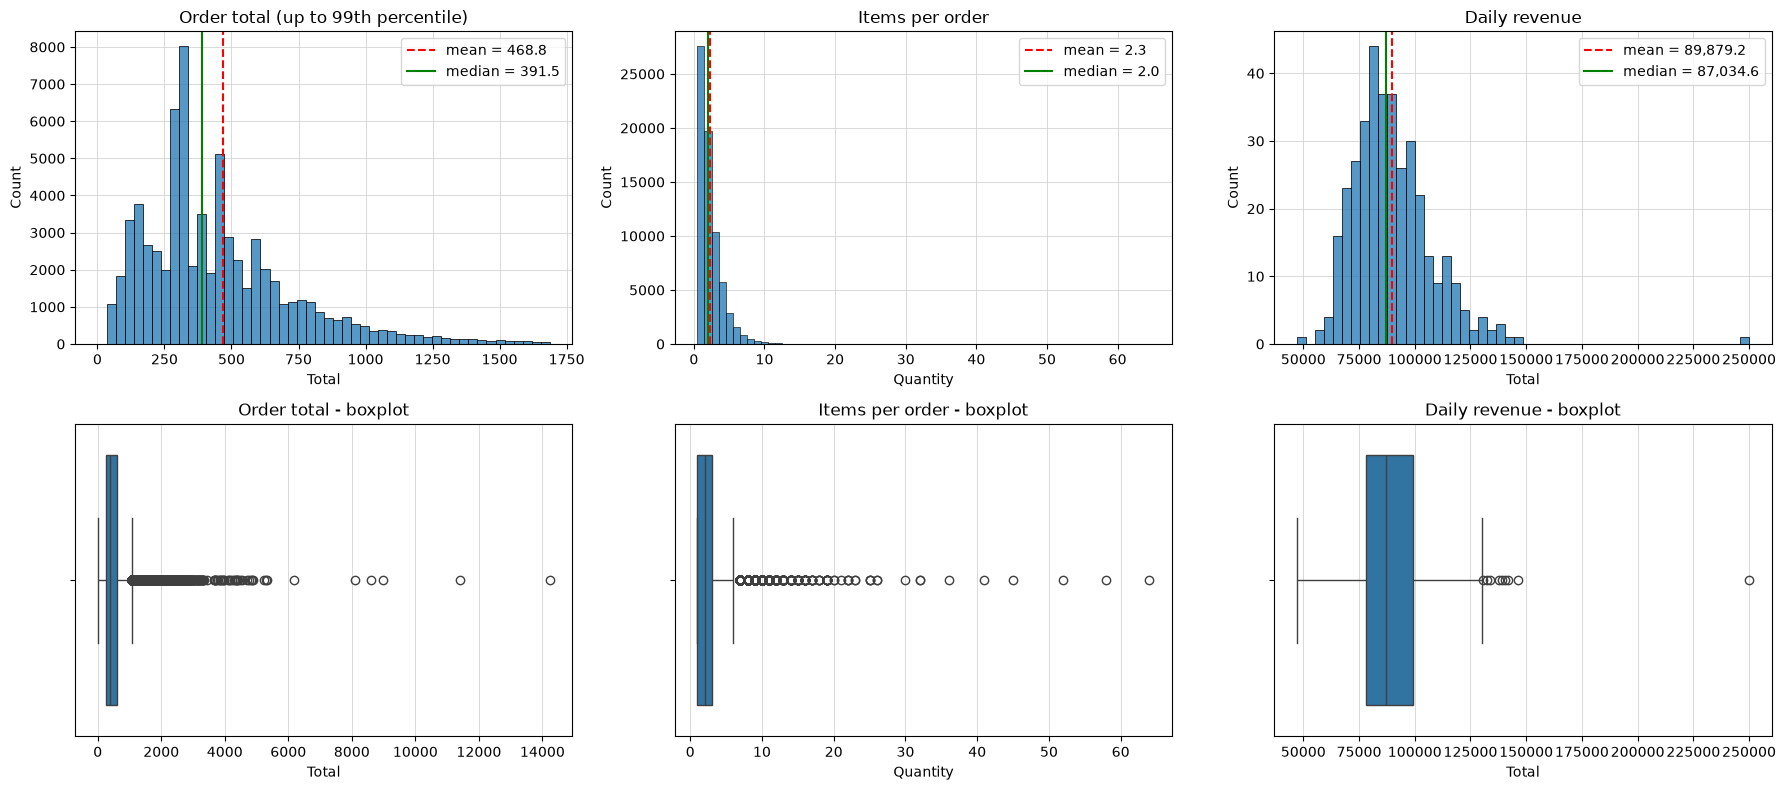

,High outliers,Share
Order total,3469,5.0%
Items per order,2051,2.9%
Daily revenue,9,2.5%


In [17]:
ds.plot_distributions(df_orders, daily)
ds.outlier_counts(df_orders, daily)

The plots confirm the skewness found above: order totals and items per order pile up on the left with a long tail of large orders, shown as many outlier points in the boxplots. These large orders are most likely groups and are real sales, so we keep them, but it's another reason to prefer the median over the mean when describing a typical customer.

<a id="step-4-4"></a>
#### Step 4.4 - Most sold products

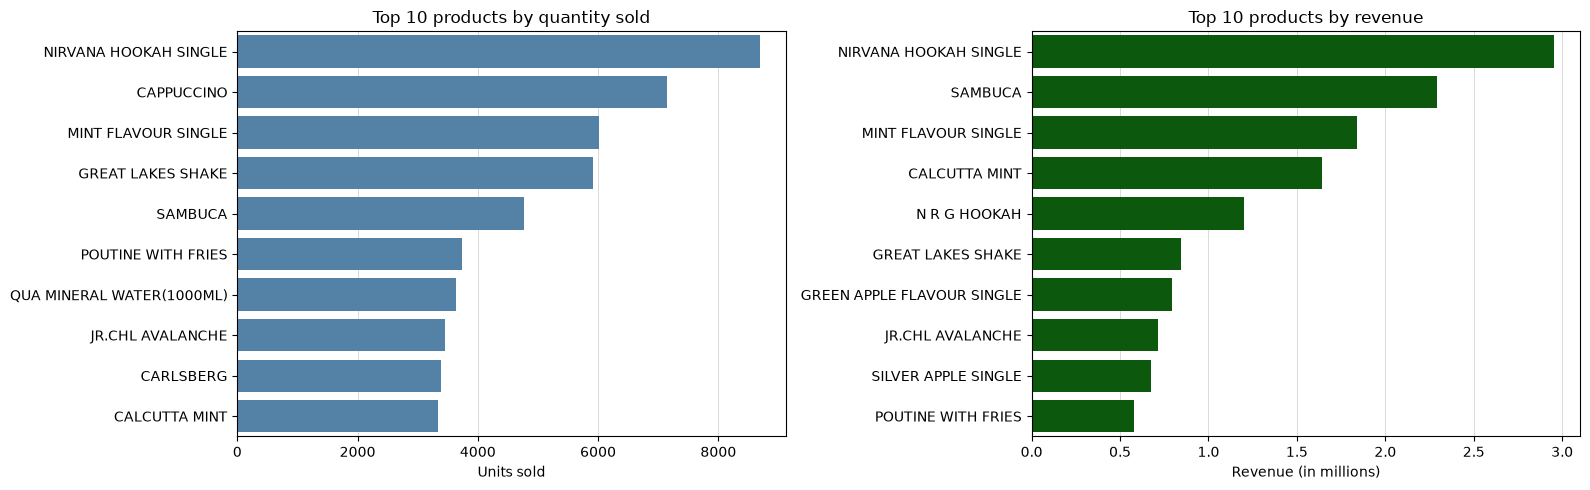

In [18]:
ds.plot_top_products(df_copy)

Hookahs are the café's main business: **NIRVANA HOOKAH SINGLE** is number one both in quantity and in revenue. **CAPPUCCINO** is the 2nd most sold item but, being cheap, it doesn't reach the top 5 in revenue, while **SAMBUCA** sells less but is the 2nd biggest earner. Which products drive volume and which drive money will be explored further in Step 6.

<a id="step-4-5"></a>
#### Step 4.5 - Most sold categories

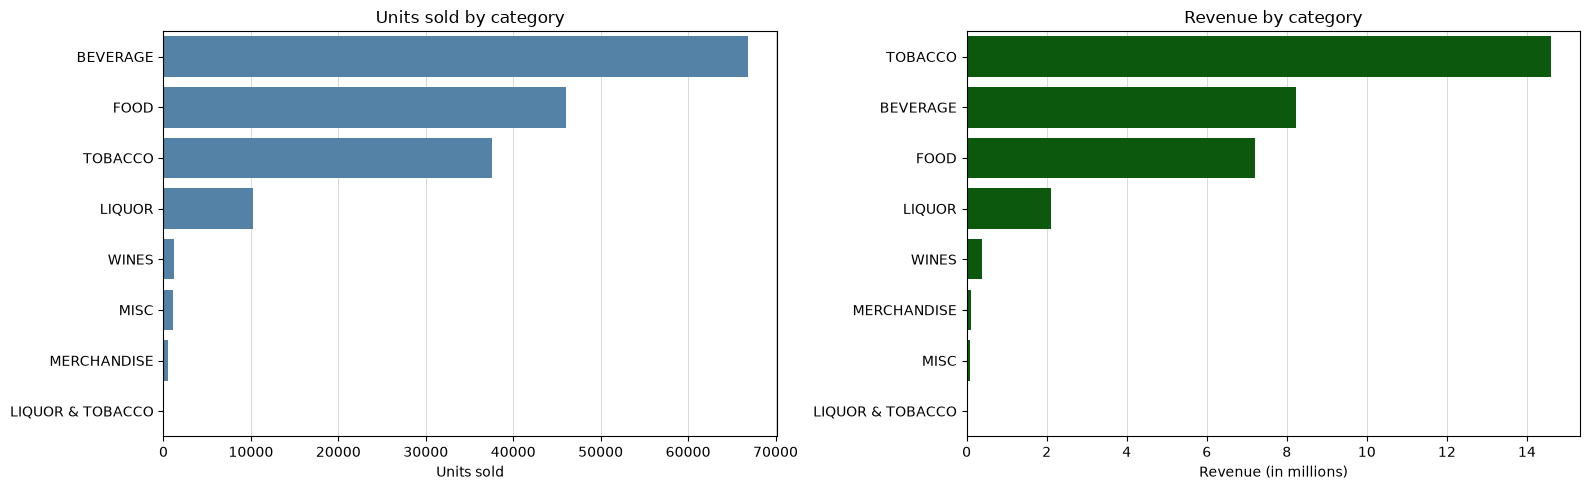

,Units sold,Revenue,Share of revenue
Category,,,
TOBACCO,"37,544","14,595,949",44.5%
BEVERAGE,"66,812","8,240,586",25.1%
FOOD,"45,999","7,216,376",22.0%
LIQUOR,"10,261","2,106,568",6.4%
WINES,"1,195","396,791",1.2%
MERCHANDISE,551,"120,074",0.4%
MISC,"1,094","86,990",0.3%
LIQUOR & TOBACCO,63,"42,562",0.1%


In [19]:
# Units sold and total revenue per category, plotted side by side
category_sales = ds.category_units(df_copy)
category_revenue = ds.category_revenue(df_copy)
ds.plot_category_sales(category_sales, category_revenue)
ds.category_table(category_sales, category_revenue)

The ranking by revenue is very different from the ranking by units:
- **Tobacco (hookah) brings in the most money**: 14.6M, **44.5%** of the revenue, while it's only 3rd in units sold.
- **Beverage** is 1st in units but 2nd in revenue (25.1%): drinks are cheap. **Food** follows closely with 22.0%.
- **Liquor** adds 6.4%, and the other four categories together make less than 2%.

Step 4.6 looks closer at the top 3, and Step 6.1 at why units and revenue rank so differently.

<a id="step-4-6"></a>
#### Step 4.6 - The top 3 categories
Step 4.5 showed that a few categories make most of the sales. Here we check which ones are the top 3 by units and by revenue, and how much of the business they make up together. The other 5 categories are grouped as "Other".

In [20]:
top3 = ds.top_categories(category_sales, category_revenue)
top3

,By units sold,By revenue
Rank,,
1,BEVERAGE,TOBACCO
2,FOOD,BEVERAGE
3,TOBACCO,FOOD


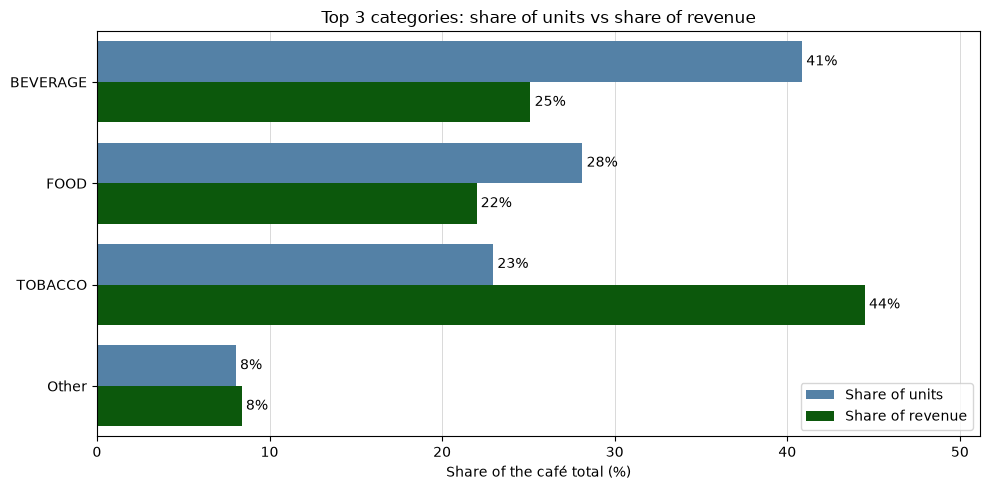

,Share of units,Share of revenue,Share of orders,Products
Category,,,,
BEVERAGE,40.9%,25.1%,53.4%,131
FOOD,28.1%,22.0%,37.8%,194
TOBACCO,23.0%,44.5%,48.4%,57
Other,8.1%,8.4%,10.7%,195
Top 3 together,91.9%,91.6%,90.6%,382


In [21]:
top3_shares = ds.top_category_shares(df_copy, category_sales.index[:3])
ds.plot_top_category_shares(top3_shares)
ds.show_top_category_shares(top3_shares)

- **The top 3 are the same by units and by revenue**: beverage, food and tobacco. Only the order changes.
- **Together they are the café**: **92% of the units, 92% of the revenue**, and at least one of them is in **91% of the orders**.
- **Each one has a different role**:
  - **Beverage brings the volume**: 41% of units and in 53% of orders, but only 25% of revenue (cheap items).
  - **Tobacco brings the money**: only 23% of units, but **44.5% of revenue** and in almost half of the orders (48%).
  - **Food is in between**: 28% of units, 22% of revenue, and the widest menu (194 products).
- **"Other"** (liquor, wines, misc, merchandise, liquor & tobacco) makes only 8% of units and revenue, but has 195 products, as many as the whole food menu. Liquor is almost only beer, and liquor & tobacco is 4 beer + hookah combo deals.

Step 6.1 looks at the revenue per unit of every category.

<a id="step-4-7"></a>
#### Step 4.7 - Top products in the top 3 categories
For each of the top 3 categories, the 5 best products by units sold (left) and by revenue (right). The title shows how much of the category those 5 products make up.

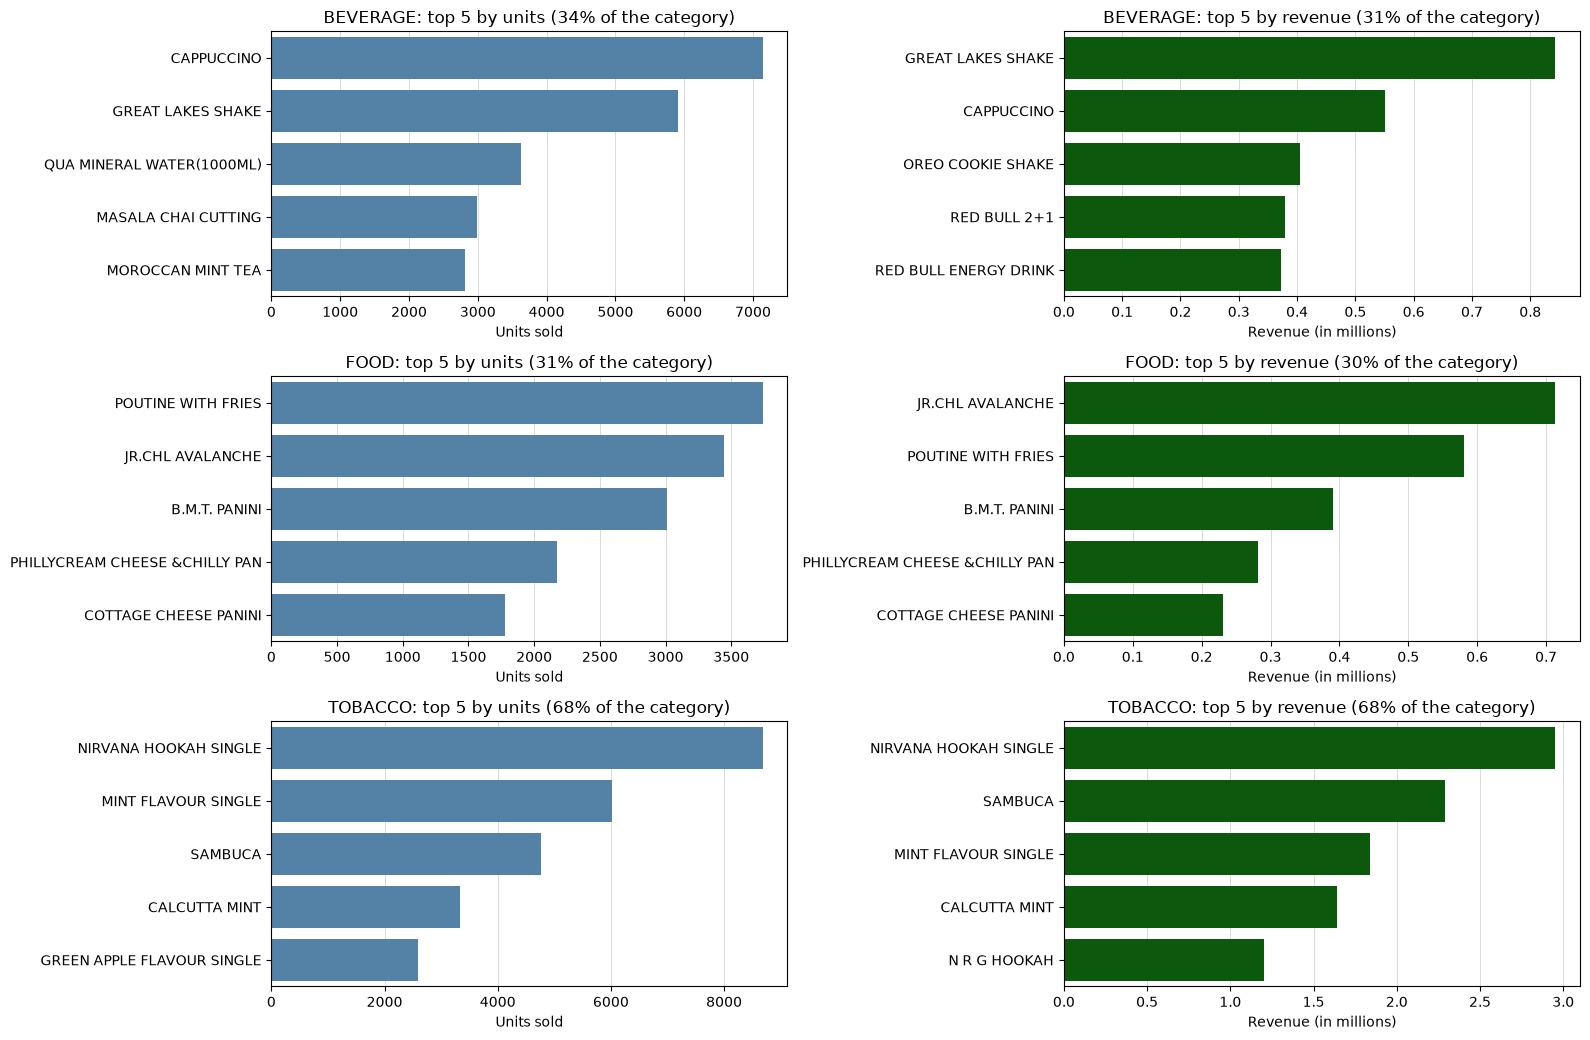

In [22]:
ds.plot_top_products_in_categories(df_copy, category_sales.index[:3])

- **BEVERAGE**: **Cappuccino** sells the most, but the **Great Lakes Shake** (moved here from FOOD in Step 3) brings in the most money. By revenue the cheap drinks (water, chai, mint tea) drop out and the more expensive **shakes and Red Bull** come in.
- **FOOD**: the same 5 products by units and by revenue (poutine, Jr. Chill Avalanche and the paninis), only **Jr. Chill Avalanche** moves to first place by revenue. Food is spread out: the top 5 make only ~30% of the category.
- **TOBACCO**: very concentrated, the **top 5 make 68%** of the category both ways. **Nirvana Hookah Single** leads both, and by revenue the **N R G hookah** replaces the cheaper Green Apple flavour. Sambuca and Calcutta Mint here are hookah flavours, not drinks.

<a id="step-5"></a>
### Step 5 - Time Series Analysis and Sales Trend Investigation
With a full year of data (Apr 2010 - Mar 2011) we look at how sales change over time: the **trend**, a **decomposition** into trend, seasonality and noise ($Y_t = T_t + S_t + \varepsilon_t$), the **recurring cycles** (hourly, weekly, monthly) and whether the series is **stationary**.

All calculations live in [time_series.py](scripts/time_series.py), so here we only show the results and what they mean.

In [23]:
df_copy = ts.add_hour(df_copy)
df_orders = ts.add_hour(df_orders)
beverages = ts.label_drinks(df_copy)   # beverages labelled hot / cold / other

<a id="step-5-1"></a>
#### Step 5.1 - Trend isolation

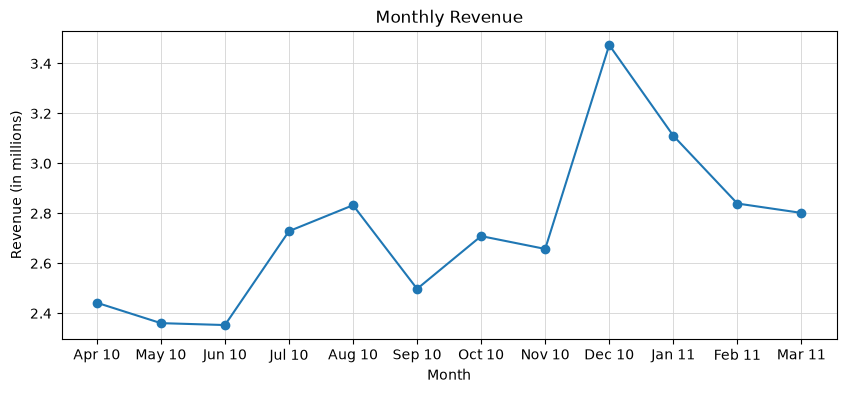

In [24]:
with ps.grid(True):   # time series: no grid
    ts.plot_monthly_revenue(daily)

Monthly revenue is lowest in **May-June** (~2.4M), rises in July-August, dips in September and then climbs to a **peak in December** (~3.5M, holidays and New Year's Eve). It falls back from January but stays above the spring 2010 level (~2.8M in March vs ~2.4M in April). Months have a different number of days, so below we look at revenue **per day** and smooth out the day-to-day noise.

A **moving average** smooths out the day-to-day noise: 7 days cancels the weekly cycle, 30 days shows the long-term direction.

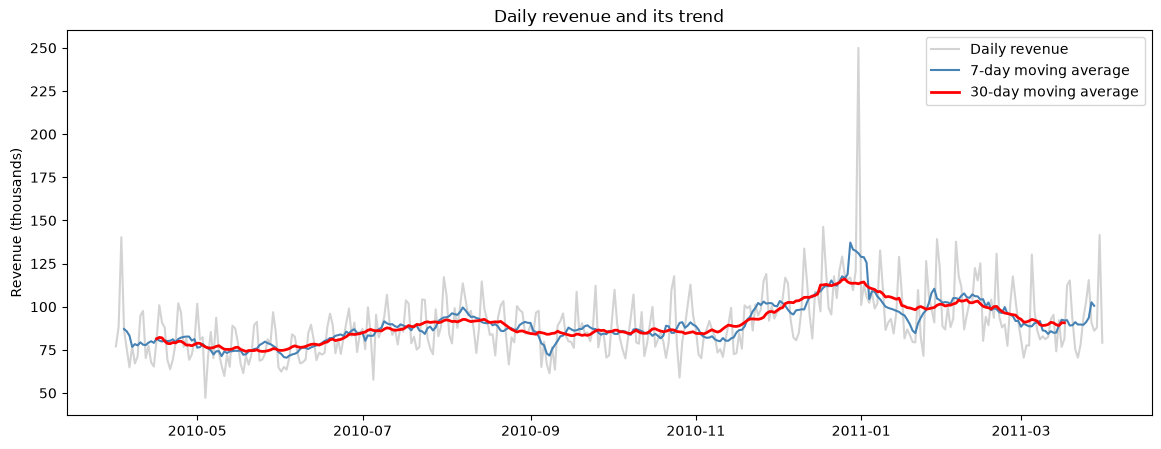

,Value
Lowest 30-day MA,"74,098 (19 May 2010)"
Highest 30-day MA,"116,016 (26 Dec 2010)"
Average day Apr-Jun 2010,"78,629"
Average day Jan-Mar 2011,"97,242"
Growth,+24%


In [25]:
ma = ts.moving_averages(daily)
with ps.grid(False):   # time series: no grid
    ts.plot_trend(ma)
ts.trend_summary(daily, ma)

- **Revenue grew over the year**: an average day in Jan-Mar 2011 brought in ~97k, against ~79k in Apr-Jun 2010 (**+24%**). Below we check whether that is more customers or customers paying more.
- The **low point** was mid-May (~74k per day), the **high point** the last week of December (~116k), driven by the holidays and New Year's Eve.
- After December sales go down again, but stay well above the spring 2010 level.
- Caveat: with only one year we can't tell real growth apart from a yearly cycle. A second year of data would settle this.

**Where does the growth come from?** Revenue can grow in three ways: **more orders** (more visits), **more items in each order**, or a **higher price per item**. We split the growth into these three parts to see which one drove it.

In [26]:
ts.growth_breakdown(df_copy, df_orders)

,Revenue per day,Orders per day,Items per order,Price per item
Apr-Jun 2010,78629.0,177.1,2.28,194.6
Jul-Sep 2010,87596.0,196.1,2.31,193.2
Oct-Dec 2010,96087.0,201.8,2.36,202.0
Jan-Mar 2011,97242.0,191.7,2.39,212.0
Change (first -> last quarter),+23.7%,+8.2%,+4.9%,+8.9%


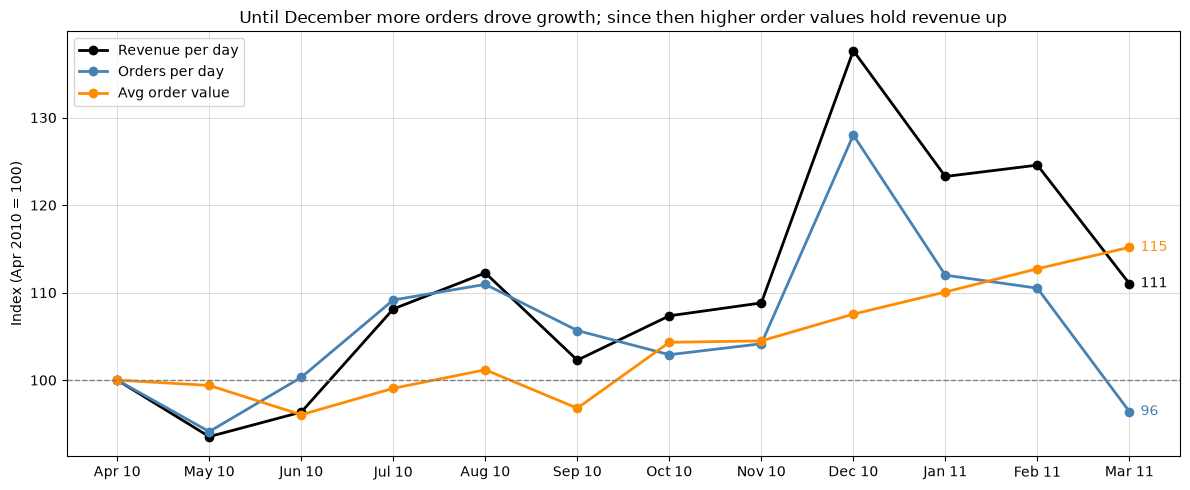

In [27]:
with ps.grid(True): # Change for background grid.
    ts.plot_growth_drivers(df_copy, df_orders)

A higher price per item can mean two things: the café **raised its prices**, or customers **chose more expensive products**. To separate them we compare the price of the **same products** in both quarters, weighting each product by how much it sold in Apr-Jun 2010 (a *Laspeyres price index*):

In [28]:
ts.same_product_price_change(df_copy)

,Value
Products sold in both quarters,265
Their share of Jan-Mar 2011 units,87%
Products whose price changed (> 1%),100
Price change of the same products,+10.8%


- **Only a third of the +24% comes from more orders** (+8% per day). The rest comes from each order being worth more: **+5% items per order** and **+9% price per item**.
- **The same products cost ~11% more** in Jan-Mar 2011 than in Apr-Jun 2010 (100 of the 265 products sold in both quarters changed price). So the higher price per item is **price increases**, not customers choosing more expensive products.
- **Two phases**: until December growth came from **more orders** (busy summer and holidays). From October the **average order value climbs every month** (+15% by March), while orders per day fall back after December. In **March 2011 there were fewer orders per day than in April 2010**.
- Business implication: revenue is held up by higher prices, but **visits are not growing anymore**. From this data alone we can't tell whether the price increases caused the drop in orders, so we look at the price changes per product in Part 3.

<a id="step-5-2"></a>
#### Step 5.2 - Structural decomposition
Daily revenue split into **trend** (7-day moving average), **weekly seasonality** (average effect of each weekday, $S_{t+7} = S_t$) and **noise** (the rest).

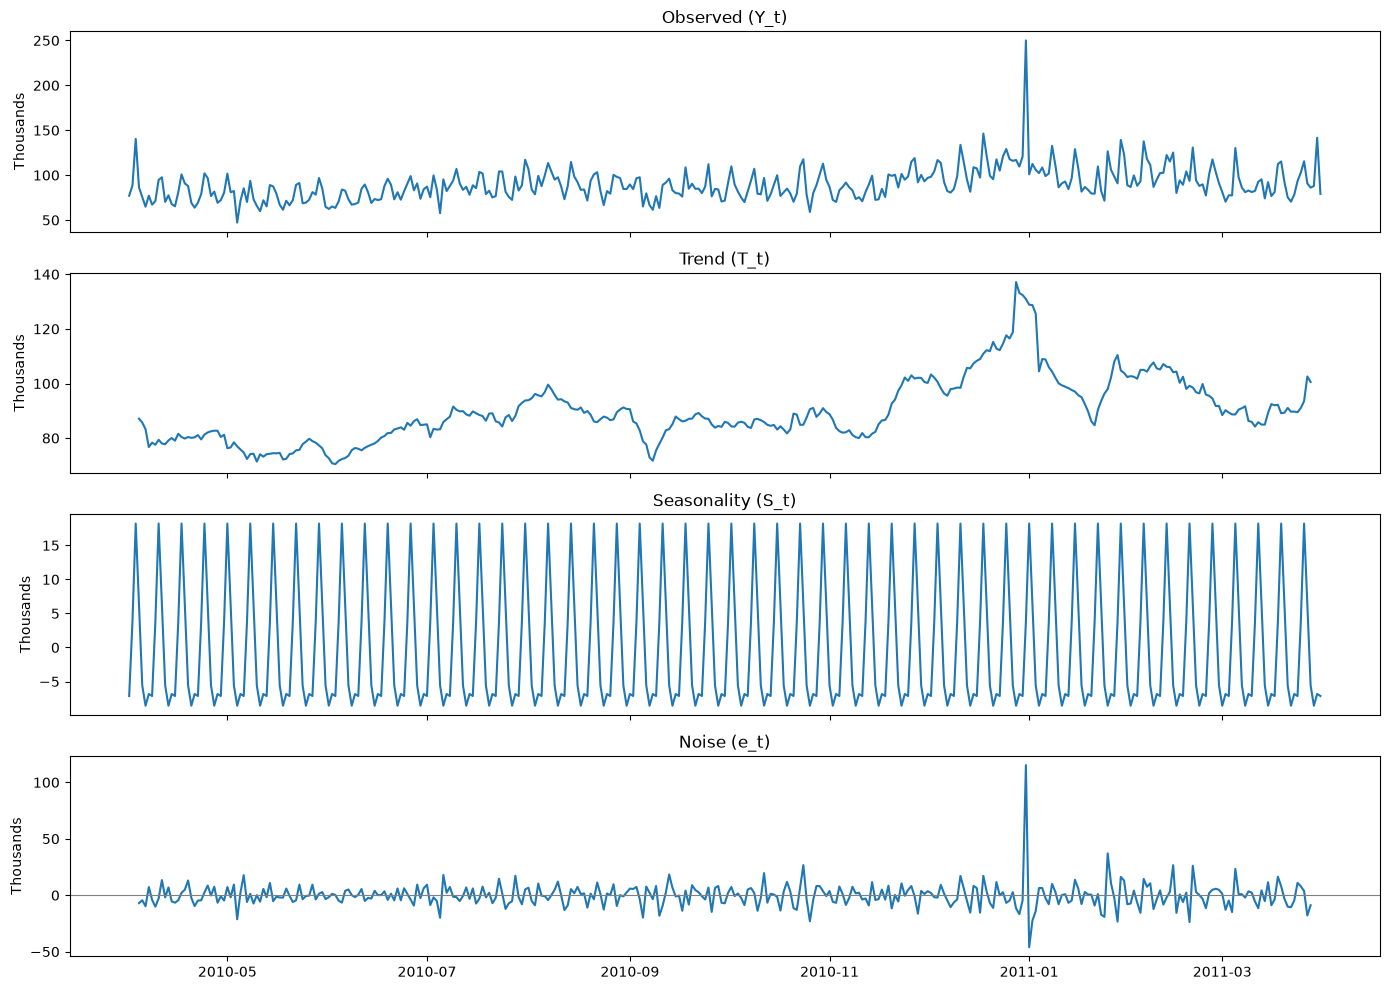

,Share of variance
Trend (T_t),0.39
Seasonality (S_t),0.24
Noise (e_t),0.34


In [29]:
dec = ts.decompose(daily, period=7)
with ps.grid(False):   # time series: no grid
    ts.plot_decomposition(dec)
ts.variance_share(dec)

In [30]:
ts.biggest_surprises(dec)

,Revenue,Expected (T_t + S_t),Noise (e_t)
Date,,,
Fri 31 Dec 2010,249995.0,134744.0,115251.0
Sat 01 Jan 2011,100973.0,147071.0,-46097.0
Tue 25 Jan 2011,126498.0,89394.0,37104.0
Sun 24 Oct 2010,117691.0,91015.0,26676.0
Mon 14 Feb 2011,125190.0,98556.0,26634.0
Sun 20 Feb 2011,130753.0,104646.0,26107.0


- Three forces of similar size: the **trend explains ~39%** of the daily variation, the **weekly cycle ~24%** and **~34% is noise**.
- **Weekly pattern**: Saturday is ~18k above the trend, Sunday ~6k and Friday ~4k, while Monday to Thursday are 6-9k below it.
- The **noise roughly doubles in the second half of the year**: busier months are less predictable, so a multiplicative model (or the log of revenue) may fit better than an additive one.
- **The biggest surprises are special days and big bookings** (checked in Step 6):
  - **New Year's Eve** made ~250k, almost 3x a normal day. The dip on 1 January is partly a side effect of that huge value on the moving average.
  - **Tue 25 Jan** was ~37k above expected: that day had a **party booking for 23 people** (14,231, the biggest bill of the year).
  - **Valentine's Day** was ~27k above a normal Monday.
  - **Sun 20 Feb** had one of the five biggest group orders (~8k). Sun 24 Oct has no obvious explanation.

<a id="step-5-3"></a>
#### Step 5.3 - Seasonality and recurring cycles
<a id="step-5-3-1"></a>
##### Step 5.3.1 - Hourly cycle

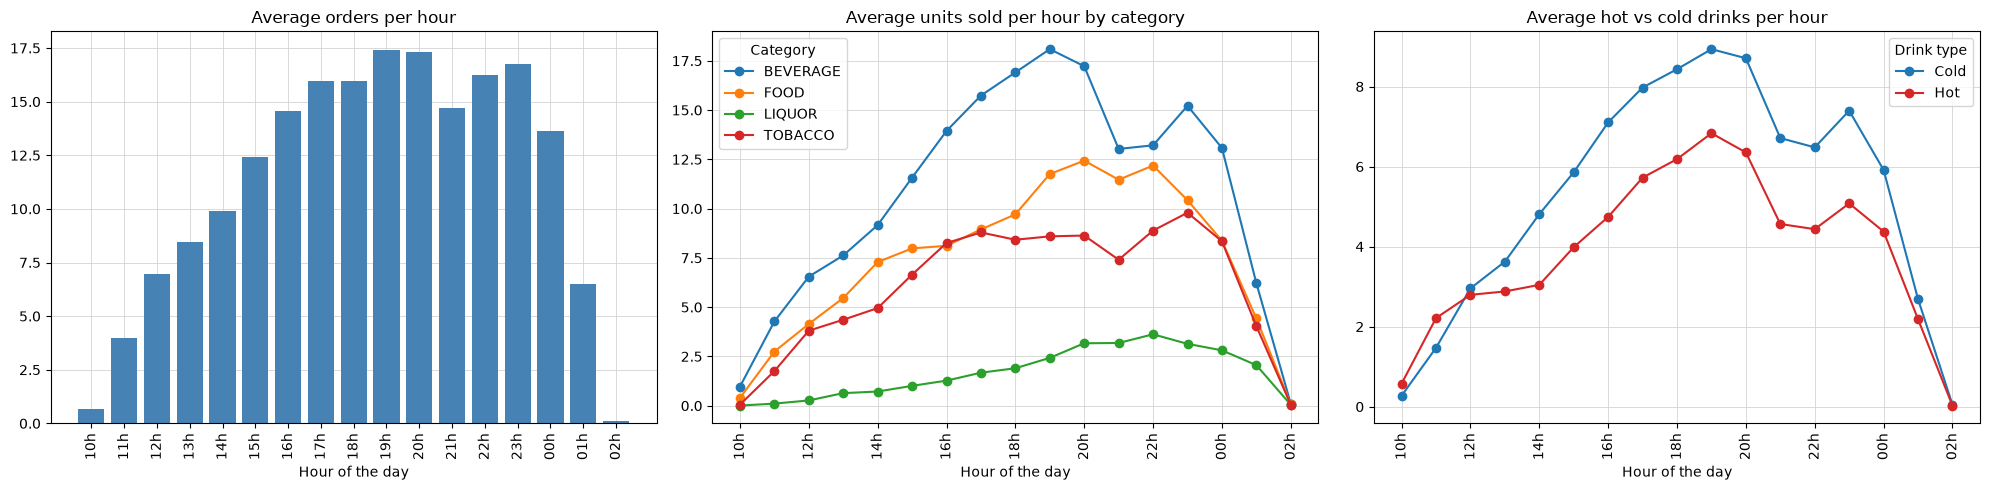

,Value
Busiest hour,19h (17.4 orders per day)
Orders before 15h,16%
Orders from 19h until closing,54%
Orders after midnight,11%


In [31]:
with ps.grid(True):   # time series: no grid
    ts.plot_hourly(df_copy, df_orders, beverages, n_days)
ts.hourly_summary(df_orders, n_days)

**There is no morning coffee rush, this is an evening and night business:**
- The café opens around **10h** and takes its last orders around **02h**.
- Only **16%** of orders come before 15h, while **54%** come from 19h until closing. The **busiest hour is 19h**, and it stays busy until midnight, apart from a short dip at 21h after the dinner rush.
- In the late morning most drinks are hot (~70% at 10h), but the volume is tiny. From the early afternoon on, about **60% of the drinks are cold** (shakes, iced teas, lemonades).
- **Liquor** peaks around 22h and **tobacco** (hookah) around 23h: the late evening is the bar/lounge part of the business.

<a id="step-5-3-2"></a>
##### Step 5.3.2 - Weekly cycle

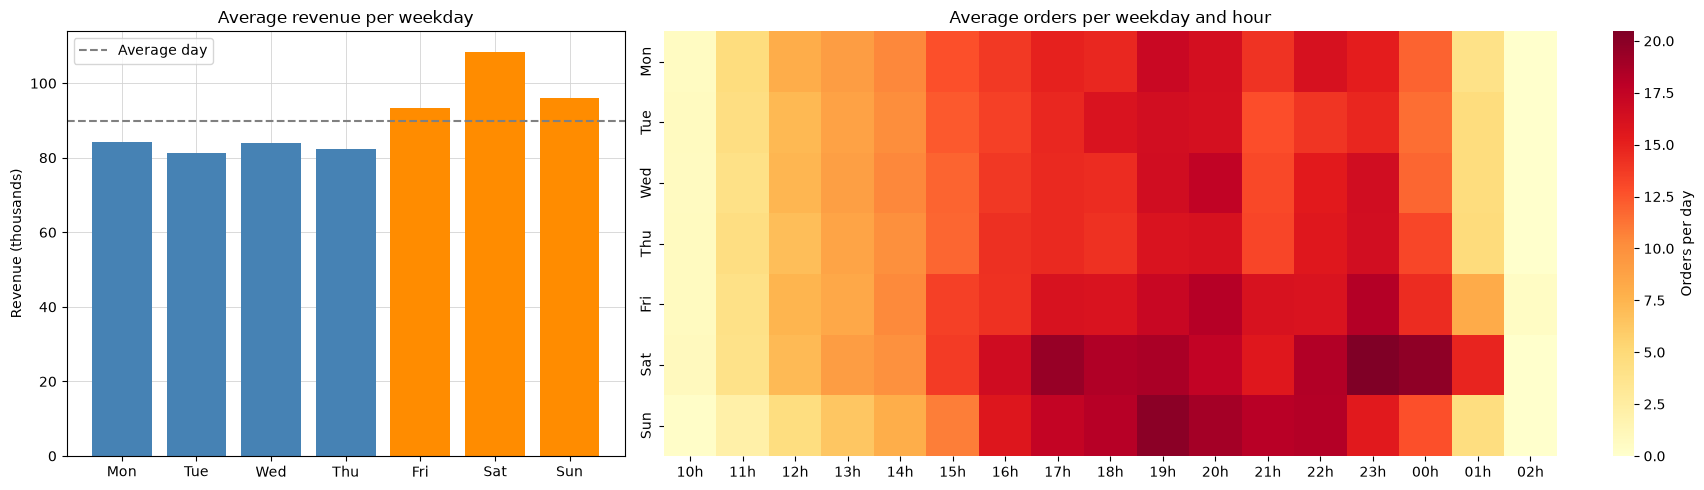

,Avg revenue,Avg orders,Seasonal effect (S_t),Avg order value
Mon,84220.0,184.0,-5585.0,458.0
Tue,81211.0,178.0,-8557.0,455.0
Wed,83868.0,182.0,-6832.0,461.0
Thu,82288.0,181.0,-7129.0,454.0
Fri,93291.0,201.0,3777.0,465.0
Sat,108501.0,224.0,18203.0,483.0
Sun,95921.0,191.0,6122.0,501.0


In [32]:
ts.plot_weekly(daily, df_orders)
ts.weekday_table(daily, df_orders, dec)

The heatmap shows that most of Saturday's extra orders come **between 00h and 02h, which is really Friday night**. So we also look at the **business day**, where orders before 06h count for the previous evening.

In [33]:
business_daily = ts.business_day_revenue(df_orders, daily)
ts.calendar_vs_business_day(daily, business_daily)

,Avg revenue (calendar day),Avg revenue (business day)
Mon,84220.0,84169.0
Tue,81211.0,81551.0
Wed,83868.0,84537.0
Thu,82288.0,85927.0
Fri,93291.0,98904.0
Sat,108501.0,98873.0
Sun,95921.0,95044.0


- **Weekends are the peak**: by calendar date Saturday makes ~109k against ~81k on Tuesday (**+34%**), with more orders (224 vs 178) and slightly bigger orders.
- By **business day**, **Friday and Saturday nights are equally strong (~99k each)**, followed by Sunday (~95k). Monday to Thursday stay around 81-86k.
- Sunday has the **highest average order value (~501)**, which suggests bigger groups or longer visits.
- The real peaks for staffing are **Friday and Saturday evenings, including the hours after midnight**.

<a id="step-5-3-3"></a>
##### Step 5.3.3 - Monthly / seasonal cycle
Beverages are labelled hot or cold from keywords in their names.
- **Left**: how many hot and cold drinks were sold each month. These numbers also go up and down with how busy the month was.
- **Right**: out of every 100 hot or cold drinks sold that month, how many were **cold**. This doesn't depend on how busy the month was, so it shows what customers **chose**. Above the dashed 50% line more cold drinks were sold, below it more hot drinks.

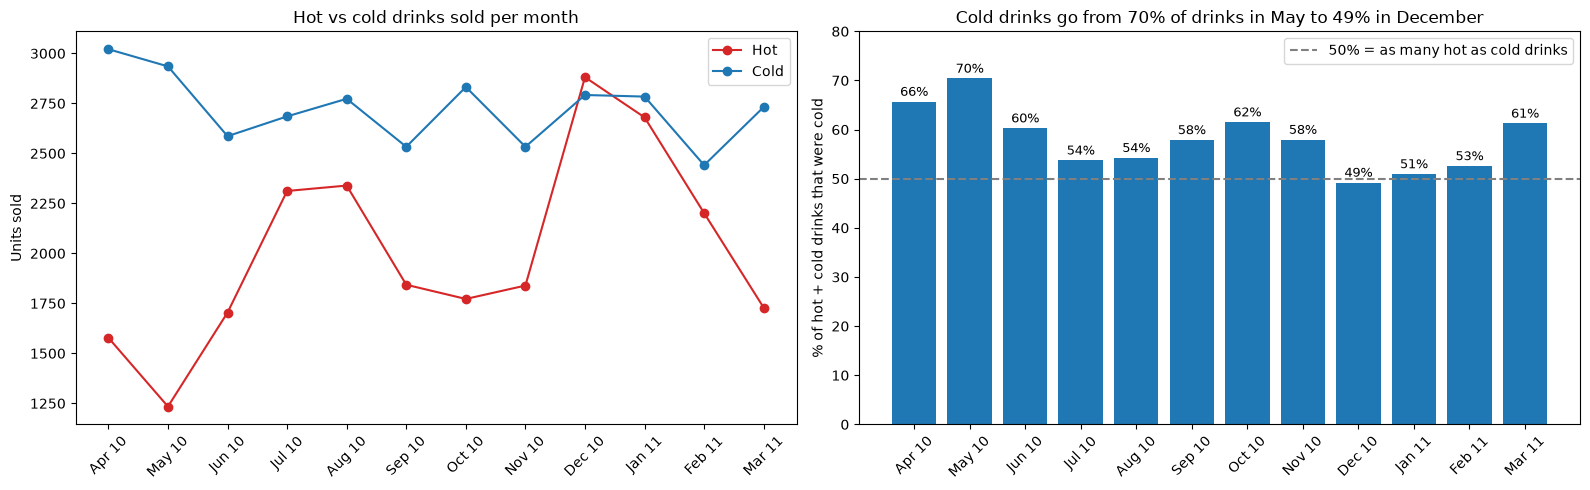

In [34]:
drinks = ts.drinks_per_month(beverages)
with ps.grid(False):   # time series: no grid
    ts.plot_drinks_per_month(drinks)

**Hot drinks drive the seasonality, not cold ones:**
- **Cold drinks are stable** all year (~2,400-3,000 per month, including the shakes): no real "summer surge".
- **Hot drinks more than double**, from ~1,230 in May to ~2,880 in December, and stay high in Dec-Jan.
- Cold drinks are the majority in every month, but their share is highest in **April-May (66-70%)** and lowest in **December-January (49-51%)**. Hot drinks also rise in July-August, which fits the cooler monsoon season if the café is in India.
- The slow months (Apr-Jun) are the ones where hot drinks sell least, so promoting cold drinks then could help fill the gap.

<a id="step-5-4"></a>
#### Step 5.4 - Detrending and stationarity
A **stationary** series keeps the same mean and spread over time, which most forecasting models need. We remove the trend by **differencing**: the change vs the day before ($Y'_t = Y_t - Y_{t-1}$) and vs the same weekday last week ($Y_t - Y_{t-7}$). We also try the weekly difference of **log revenue**, and check every series with the **Augmented Dickey-Fuller (ADF) test** (H0: the series is not stationary, so a p-value below 0.05 means stationary).

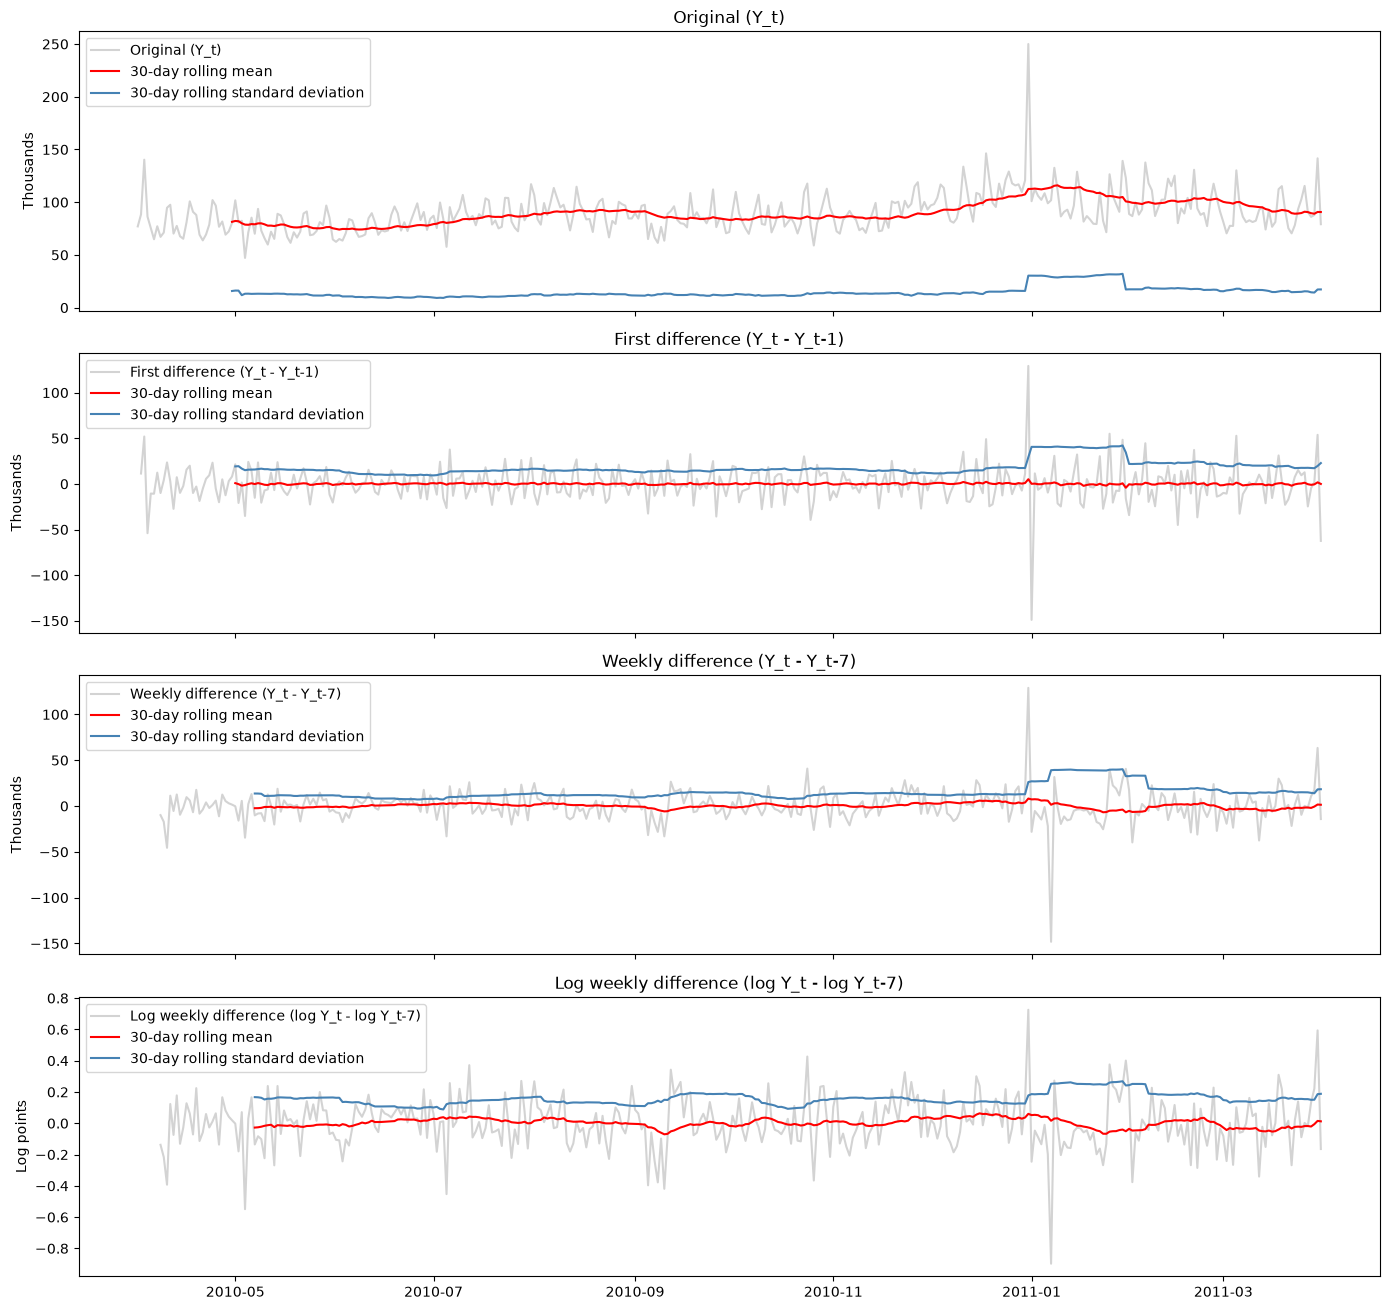

,Original (Y_t),First difference (Y_t - Y_t-1),Weekly difference (Y_t - Y_t-7),Log weekly difference (log Y_t - log Y_t-7)
Mean 1st half,83199.75,-29.20,-43.98,0.00
Mean 2nd half,96522.08,40.72,569.03,0.01
Std 1st half,13405.08,14927.07,11796.08,0.15
Std 2nd half,20520.31,23524.06,21316.60,0.18
Std ratio (2nd / 1st half),1.53,1.58,1.81,1.23
Autocorrelation lag 1,0.44,-0.31,0.06,0.11
Autocorrelation lag 7,0.57,0.26,-0.35,-0.35
ADF p-value,0.11,0.00,0.00,0.00


In [35]:
diffs = ts.differenced_series(daily)
with ps.grid(False):   # time series: no grid
    ts.plot_differencing(diffs)
ts.stationarity_table(diffs)

- The **original series is not stationary**: the average day rises from ~83k to ~97k between the two halves of the year, the spread grows too, and the ADF test can't reject non-stationarity (p = 0.11).
- **Differencing removes the trend**: all differenced series have a mean close to 0 and pass the ADF test (p < 0.01).
- Only the **weekly differences also remove the weekly cycle** (the first difference still has a lag-7 autocorrelation of 0.26).
- The **spread still grows** with plain differencing (the std of the weekly difference is 1.8x higher in the second half). Taking the **log first** reduces this to 1.2x, so for modelling we recommend **log revenue + weekly differencing**.

<a id="step-5-5"></a>
#### Step 5.5 - Key takeaways
1. **Revenue grew, but mostly through prices**: +24% per day from Apr-Jun 2010 to Jan-Mar 2011. Only +8% comes from more orders, the rest from bigger and more expensive orders (the same products cost ~11% more). Orders per day peaked in December and by March were below April 2010.
2. **It's an evening/night café**: more than half of the orders come after 19h and there is no morning rush. The quiet late morning and lunch hours are the biggest room for growth.
3. **Friday and Saturday nights are the strongest**, about +19% above Monday-Wednesday, with many sales after midnight.
4. **Hot drinks drive the seasons**: they more than double from May to December while cold drinks stay flat.
5. **Special days matter**: New Year's Eve was almost 3x a normal day, and party bookings, group orders and Valentine's Day also stand out.
6. **For forecasting**: use log revenue with weekly differencing (stationary by the ADF test) and add calendar features (weekday, special days, business day) in Step 7.

<a id="step-6"></a>
### Step 6 - Category Performance and Relationship Discovery
Now we look at **what** the café sells: how each category performs, how concentrated sales are, how the mix changes through the day, which products sell best per month and season, how variables relate to each other and which anomalies we found.

In [36]:
df_copy = cat.add_daypart(df_copy)
df_orders = cat.add_daypart(df_orders)

<a id="step-6-1"></a>
#### Step 6.1 - Category performance
Steps 4.5 and 4.6 showed how much each category sells and earns. Here we look at **why** units and revenue rank so differently, with two numbers per category:
- **Revenue per unit**: the price level of the category
- **Revenue per product per month**: how much an item on the menu earns in a month on sale. Products are on sale for very different lengths of time (a New Year's Eve special for 1 day, a regular product all year, see Step 6.2), so we divide by the total time the products were on sale instead of by the number of products.

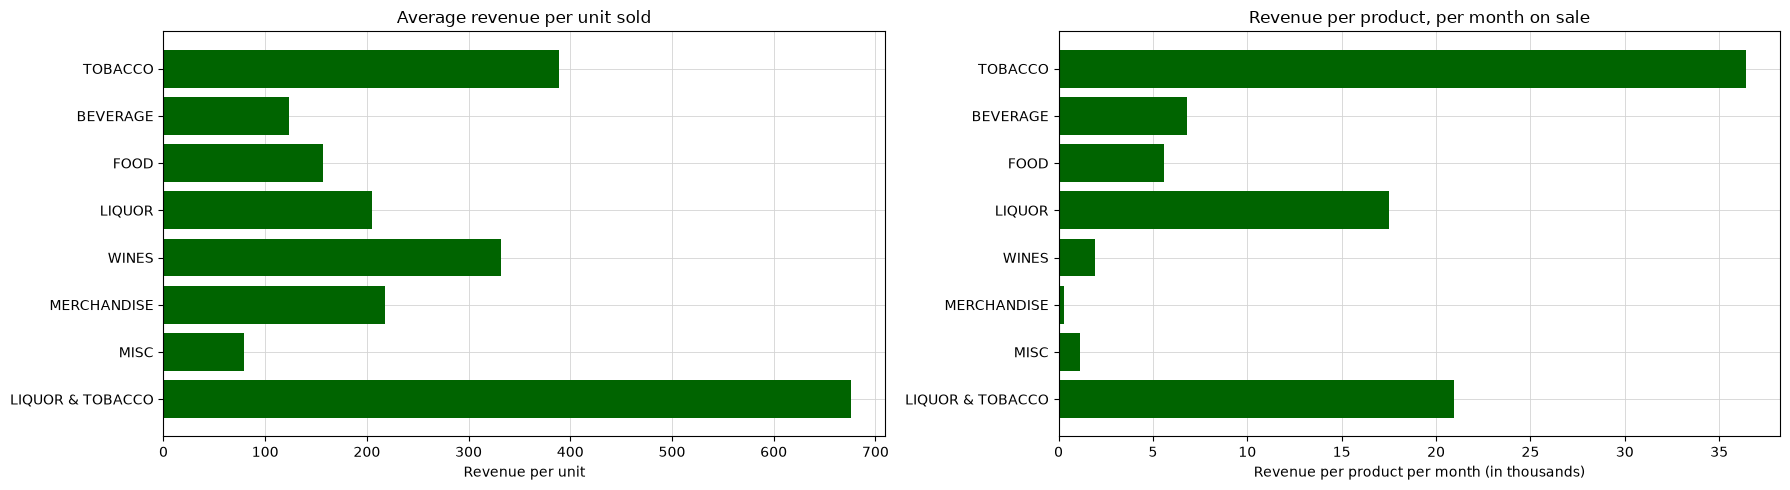

,Revenue per unit,Products,Revenue per product per month
Category,,,
TOBACCO,389,57,"36,402"
BEVERAGE,123,131,"6,790"
FOOD,157,194,"5,577"
LIQUOR,205,33,"17,526"
WINES,332,58,"1,926"
MERCHANDISE,218,87,286
MISC,80,13,"1,148"
LIQUOR & TOBACCO,676,4,"20,932"


In [37]:
performance = cat.category_performance(df_copy, df_orders)
cat.plot_category_performance(performance)
cat.show_category_performance(performance)

- **Price explains the gap between units and revenue**: a hookah brings in **~389 per unit**, 3x a drink (~123) and 2.5x a food item (~157). That's why tobacco makes 45% of the revenue with 23% of the units.
- **Tobacco's menu works the hardest**: **~36k per product per month**, 2x liquor (~18k), 5x beverage (~7k) and 6.5x food (~5.6k).
- **Liquor is the surprise**: only 33 products (mostly beer), but each earns ~18k a month, more than twice a drink or a dish.
- **Food has the longest menu (194 products)** and earns the least per product of the top 3: a long menu with many small sellers.
- **Wines and merchandise are expensive per unit, but earn little per product** (~1.9k and ~0.3k a month).
- **Liquor & tobacco** has the highest price per unit (~676) because its 4 products are beer + hookah combo deals.

<a id="step-6-2"></a>
#### Step 6.2 - Concentration of sales (Pareto)
The 80/20 rule says a small part of the products often makes most of the revenue. With 577 different products sold during the year, how concentrated is the café's revenue?

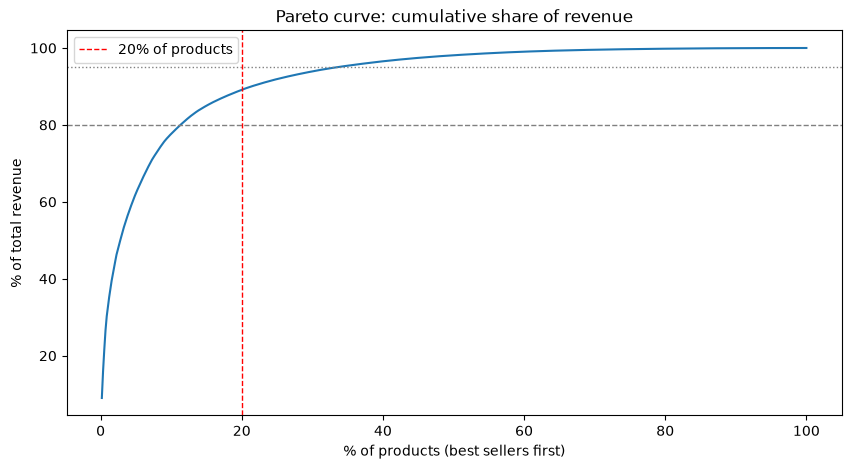

,Value
Products making 50% of revenue,17 (3% of products)
Products making 80% of revenue,66 (11% of products)
Products making 95% of revenue,194 (34% of products)


In [38]:
with ps.grid(False):
    cat.plot_pareto(df_copy)
cat.pareto_summary(df_copy)

- Revenue is **very concentrated**: **17 products (3%) make half of the revenue** and **66 products (11%) make 80%**, even stronger than the 80/20 rule.
- That leaves a long tail of products that sell very little. But can we simply cut them?

**Which products really sell too little?**

Counting units over the whole year is misleading, because **not every product was on sale all year**: some were sold on one evening only (New Year's Eve specials), some only arrived with the new menu on 7 January 2011, and some were dropped before it. A product sold for 1 day can't reach 12 units in a year, even if it sold 10 that evening.

We only see sales, not the menu, so we use the time between a product's **first and last sale** as the time it was on sale, and measure **units per day on sale**. Every product gets a lifecycle status:
- **Special**: all its sales fall within one week
- **New**: first sold from 7 January 2011 (new menu)
- **Retired**: last sold before 7 January 2011
- **Regular**: on sale before and after the new menu started

The last column counts the products that sold **fewer than 12 units in the whole year**. That looks like "less than once a month", but it ignores how long each product was on sale:

In [39]:
lifecycle = cat.product_lifecycle(df_copy)
cat.lifecycle_summary(lifecycle)

,Products,Share of the café's revenue,Typical days on sale (median),Typical units sold per day on sale (median),Products with fewer than 12 units in the year
Status,,,,,
Regular,233,86.9%,360.0,0.42,36
New (from Jan 2011),80,2.5%,80.0,0.50,14
Retired (before Jan 2011),173,10.0%,227.0,0.25,59
Special (sold within a week),91,0.7%,1.0,1.00,82


Only **36 of the 191 products with fewer than 12 units are regular products**. The others are specials (82), retired (59) or new (14), so their low yearly total says nothing about how popular they are.

So we only look at the products **still on the menu in 2011** (regular and new), and count those that sell less than once a week or once a month **per day on sale**:

In [40]:
cat.slow_sellers(lifecycle)

,Products on the 2011 menu,Sell less than once a week,Sell less than once a month,Café revenue from the products selling less than once a week
Category,,,,
MERCHANDISE,39,39,19,0.27%
BEVERAGE,110,18,0,0.18%
WINES,17,10,2,0.35%
TOBACCO,31,5,2,0.03%
FOOD,98,4,0,0.01%
LIQUOR,16,2,0,0.07%
LIQUOR & TOBACCO,2,0,0,0.00%
Total,313,78,23,0.91%


In [41]:
# The slowest food and drinks still on the menu
cat.slowest_products(lifecycle)

,Category,Status,Units sold in the year,Days on sale,Units sold per day on sale
Item Desc,,,,,
NEW ORLEANS BLUE (AULAIT),BEVERAGE,Regular,10,289,0.035
BOTTLED WATER (1LITRE),BEVERAGE,Regular,10,271,0.037
HOUSE BLEND DE CAFFE (AU LAIT),BEVERAGE,Regular,10,244,0.041
NEW ORLEANS BLUE (REG),BEVERAGE,Regular,15,293,0.051
HAWAIIAN KONA FANCY (AU LAIT),BEVERAGE,Regular,19,347,0.055
JAVA ESTATES (REG),BEVERAGE,Regular,18,321,0.056
JAVA ESTATES (AULAIT),BEVERAGE,Regular,17,294,0.058
COLUMBIAN SUP DCAFE (AU LAIT),BEVERAGE,Regular,17,285,0.060
GUATEMALA ANTIGUA (AULAIT),BEVERAGE,Regular,21,317,0.066


- **The real tail is much smaller than it looked**: of the 313 products on the 2011 menu, **78 sell less than once a week** and **23 less than once a month**. Together the 78 bring in **0.9% of the revenue**.
- **Half of them are merchandise**: all 39 merchandise items (T-shirts, notebooks, mugs, ...) sell less than once a week. They don't take kitchen time, so the cost of keeping them is mostly stock.
- **On the kitchen and bar side, the tail is speciality coffee**: 18 drinks sell less than once a week, and **15 of them are speciality coffees**: 8 origins and blends (*Java Estates*, *New Orleans Blue*, *Hawaiian Kona*, *Guatemala Antigua*, ...), most of them both as regular and au lait. Food has only 4 slow products.
- Business implication: there's **no need to cut a third of the menu**. A small clean-up is enough: **group the speciality coffees** into fewer options, review the **10 slow wines**, and keep merchandise as a small corner. Before removing a product we would still check in Part 2 if it's bought together with best sellers.
- Limitation: a product that was on the menu but never sold is invisible in this data, and a product that only sold now and then over a long period counts as "on sale" the whole time.

<a id="step-6-3"></a>
#### Step 6.3 - Category mix through the day and the week
Step 5 showed *when* the café is busy. Here we look at *what* it sells at those moments. We split the day into parts based on the opening hours.

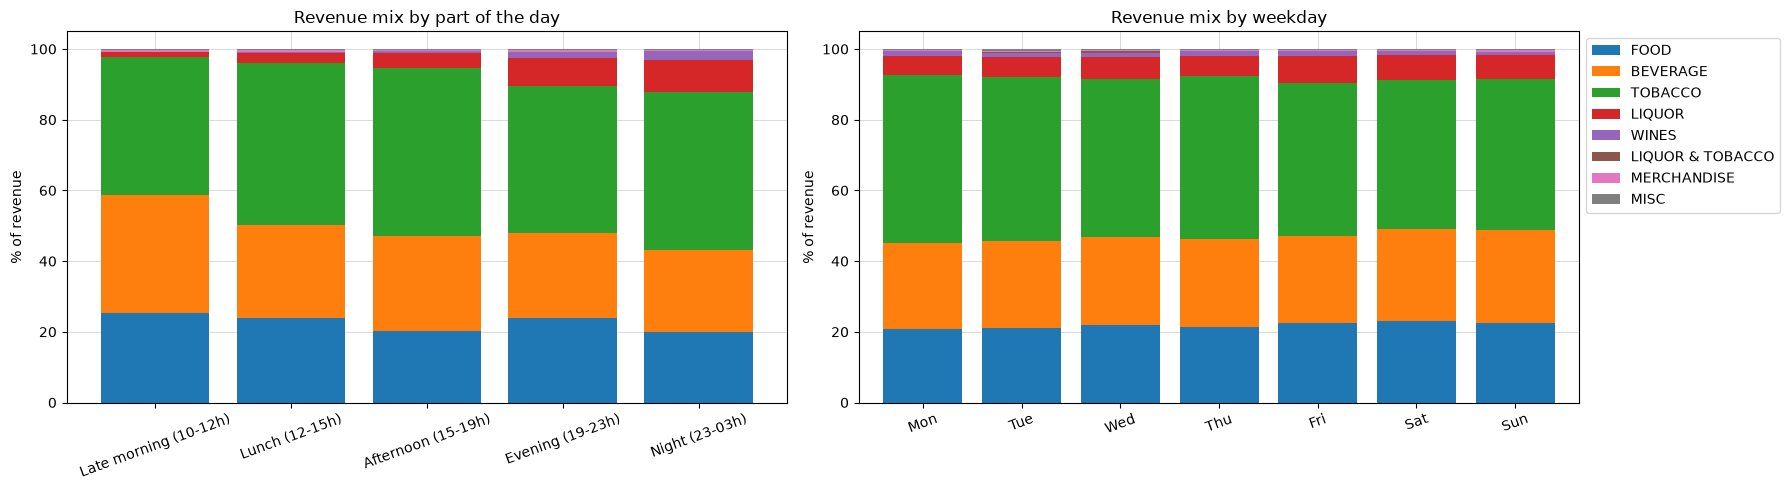

,Orders,Revenue,Avg_order_value,Share of revenue,Top category
Daypart,,,,,
Late morning (10-12h),1702,"613,387",360.0,2%,TOBACCO (39%)
Lunch (12-15h),9248,"3,858,510",417.0,12%,TOBACCO (46%)
Afternoon (15-19h),21502,"9,716,733",452.0,30%,TOBACCO (47%)
Evening (19-23h),23971,"11,562,562",482.0,35%,TOBACCO (42%)
Night (23-03h),13559,"7,054,702",520.0,22%,TOBACCO (45%)


In [42]:
cat.plot_category_mix(df_copy)
cat.daypart_table(df_copy, df_orders)

- **Hookah is the biggest earner in every part of the day** (39-47% of revenue), even at lunch. It's not only a night product.
- **Drinks matter most in the late morning** (33% of revenue), **alcohol grows through the day**: liquor goes from 1% in the late morning to 9% at night, wine from 0.1% to 2.3%.
- The **evening (19-23h) brings in the most revenue (35%)**, followed by the afternoon (30%) and the night (22%). The late morning is only 2%.
- **Orders get bigger as the day goes on**: the average order is ~360 in the late morning and ~520 at night.
- The **mix is almost the same every weekday**. From Friday to Sunday people order a bit more food and liquor (and drinks on Sat-Sun), so tobacco's share drops from ~45-48% to ~42-43%.

**The top 7 products of the top 3 categories through the day and the week**

The same mix as above, but for the **7 best-selling products** of each of the top 3 categories (Step 4.6). Each bar shows how the units of those 7 products are split, so we can see which of them gain or lose popularity during the day and the week.

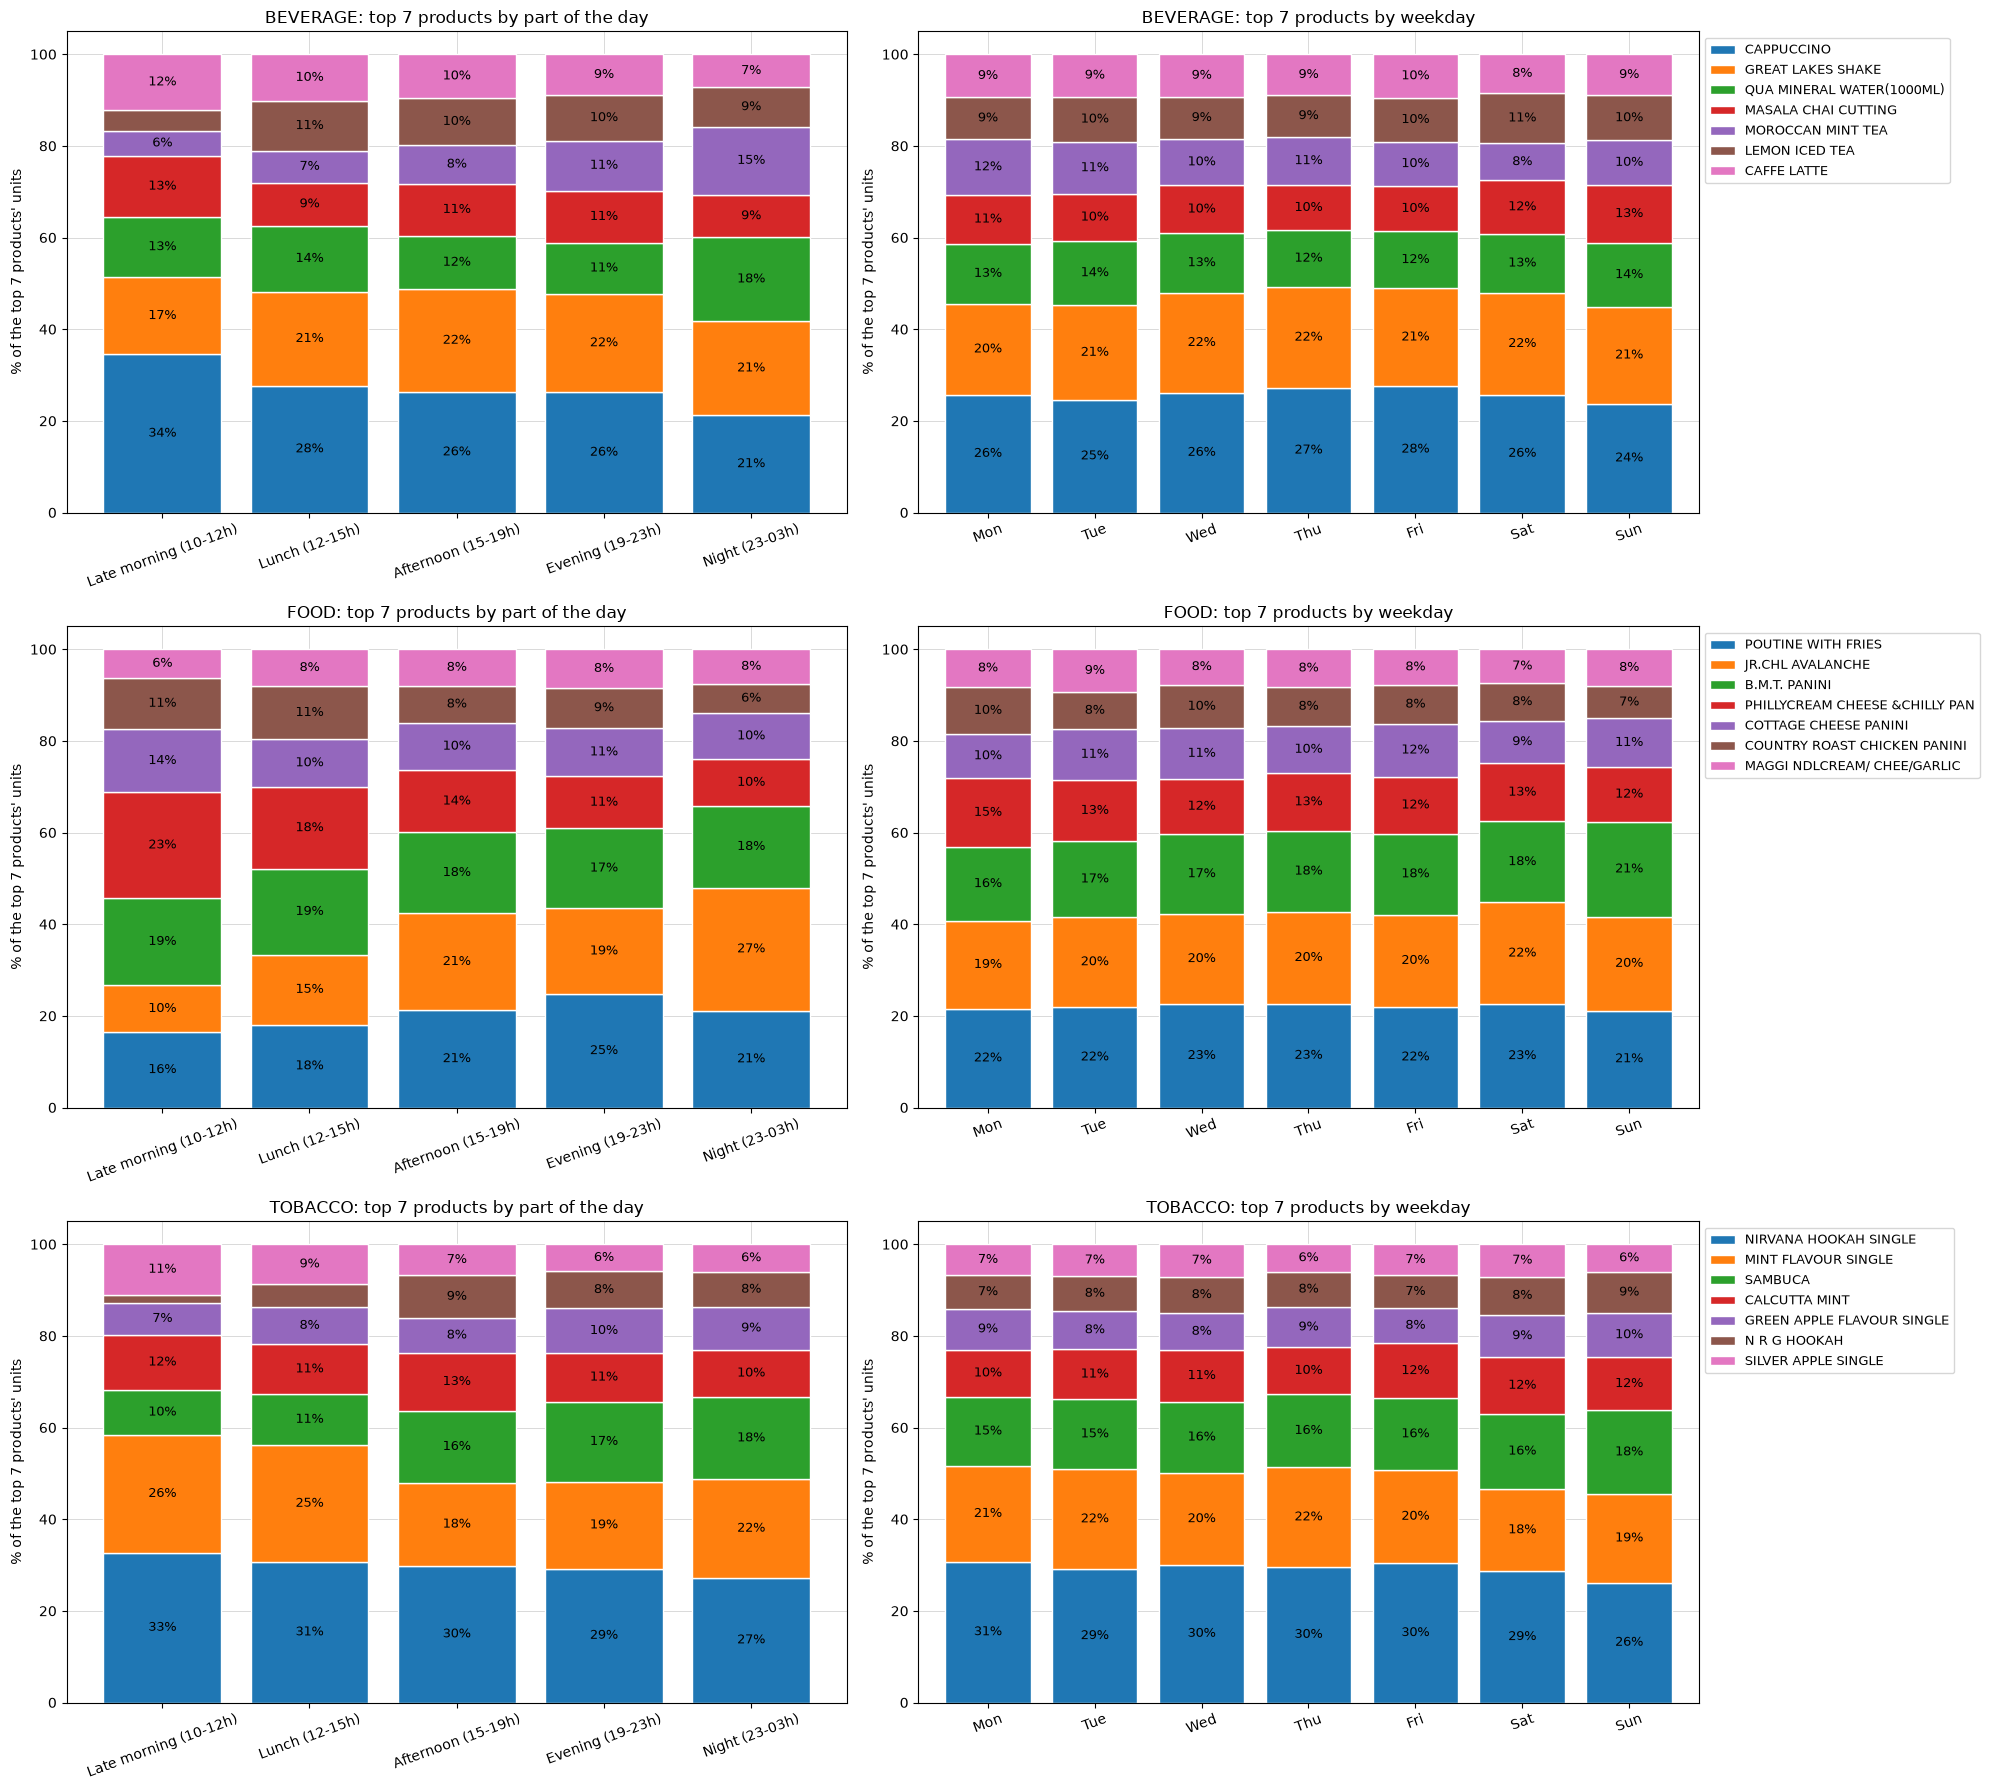

In [43]:
cat.plot_top_product_mix(df_copy)

- **The time of day matters much more than the weekday**: the bars by weekday are almost the same every day, while the bars by part of the day clearly shift. The only weekday effect is on **Sunday**: a bit more Sambuca (18% vs ~15%), B.M.T. panini (21% vs ~17%) and masala chai (13% vs ~10%).
- **BEVERAGE**: **cappuccino is a daytime drink**, 34% of these drinks in the late morning and 21% at night, and caffe latte follows the same pattern (12% -> 7%). **Moroccan mint tea** goes the other way, from 5% to 15% at night, and water is most popular at night (18%). Lemon iced tea is rare in the late morning (5%) and takes ~10% from lunch on.
- **FOOD**: the **Phillycream cheese & chilly panini is the morning favourite** (23% in the late morning, 10% at night), while **Jr. Chill Avalanche** grows from 10% to 27% at night and **poutine** from 16% to 25% in the evening. The B.M.T. panini is stable all day (~18%).
- **TOBACCO**: the cheaper **Nirvana** (33% -> 27%), **Mint flavour** (26% -> 18-22%) and **Silver Apple** (11% -> 6%) are strongest in the late morning and at lunch. From the afternoon the premium **Sambuca** (10% -> 18%) and **N R G** (2% -> 9%) take over part of their share.

<a id="step-6-4"></a>
#### Step 6.4 - Most sold products per month and season
Seasons are the four quarters of the data year.

<a id="step-6-4-1"></a>
##### Step 6.4.1 - Top products per month

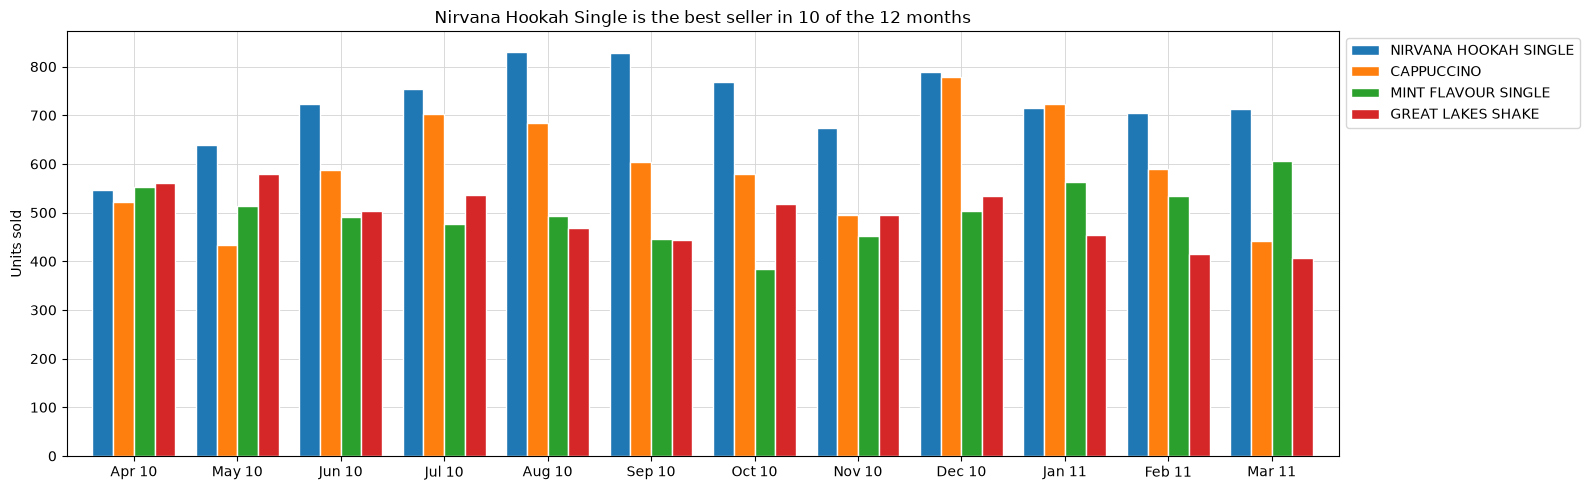

In [44]:
cat.plot_top_products_per_month(df_copy, n=4)

In [45]:
cat.top_products_per_period(df_copy, df_copy["Date"].dt.to_period("M"))

Rank,1,2,3
Period,,,
2010-04,GREAT LAKES SHAKE (560),MINT FLAVOUR SINGLE (553),NIRVANA HOOKAH SINGLE (547)
2010-05,NIRVANA HOOKAH SINGLE (639),GREAT LAKES SHAKE (580),MINT FLAVOUR SINGLE (514)
2010-06,NIRVANA HOOKAH SINGLE (723),CAPPUCCINO (588),GREAT LAKES SHAKE (503)
2010-07,NIRVANA HOOKAH SINGLE (754),CAPPUCCINO (703),GREAT LAKES SHAKE (536)
2010-08,NIRVANA HOOKAH SINGLE (831),CAPPUCCINO (685),MINT FLAVOUR SINGLE (494)
2010-09,NIRVANA HOOKAH SINGLE (828),CAPPUCCINO (605),MINT FLAVOUR SINGLE (445)
2010-10,NIRVANA HOOKAH SINGLE (769),CAPPUCCINO (580),SAMBUCA (570)
2010-11,NIRVANA HOOKAH SINGLE (673),GREAT LAKES SHAKE (496),CAPPUCCINO (495)
2010-12,NIRVANA HOOKAH SINGLE (790),CAPPUCCINO (778),GREAT LAKES SHAKE (535)


<a id="step-6-4-2"></a>
##### Step 6.4.2 - Top products per season

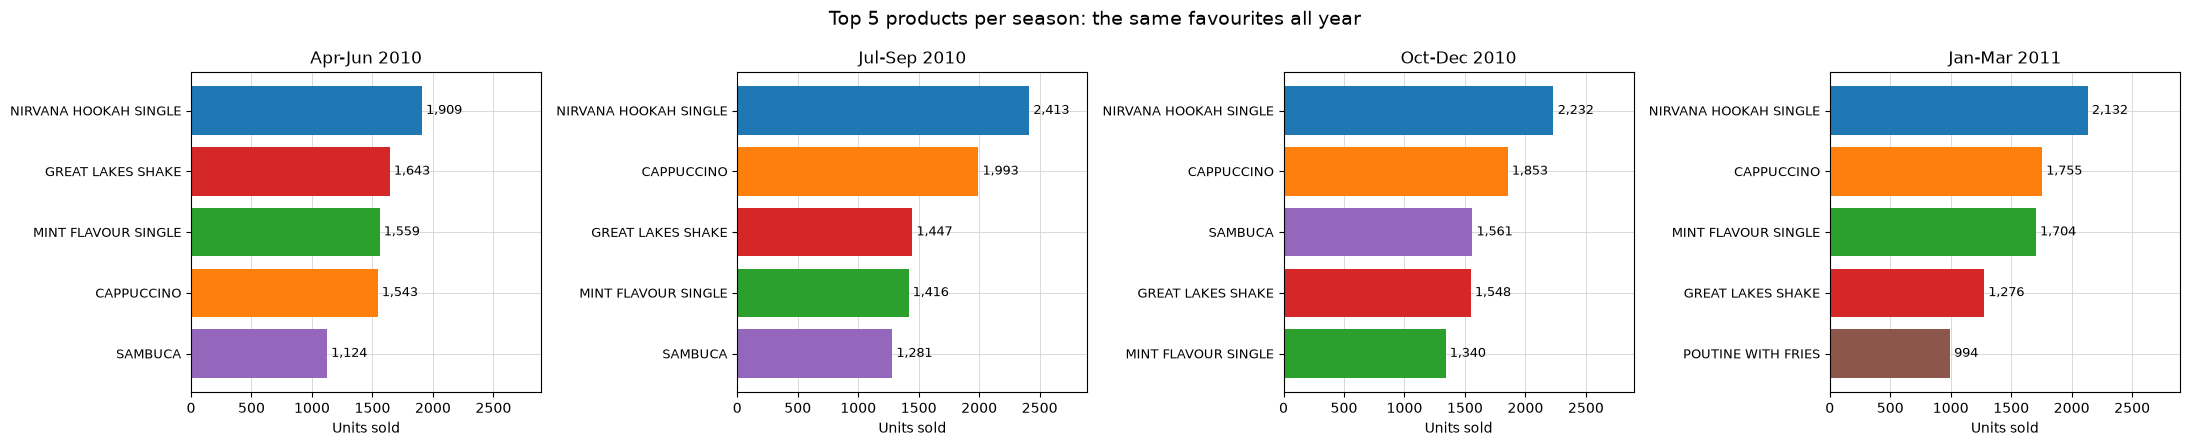

In [46]:
cat.plot_top_products_per_season(df_copy)

In [47]:
cat.top_products_per_period(df_copy, cat.season_of(df_copy["Date"]), n=5)

Rank,1,2,3,4,5
Period,,,,,
Apr-Jun 2010,NIRVANA HOOKAH SINGLE (1909),GREAT LAKES SHAKE (1643),MINT FLAVOUR SINGLE (1559),CAPPUCCINO (1543),SAMBUCA (1124)
Jul-Sep 2010,NIRVANA HOOKAH SINGLE (2413),CAPPUCCINO (1993),GREAT LAKES SHAKE (1447),MINT FLAVOUR SINGLE (1416),SAMBUCA (1281)
Oct-Dec 2010,NIRVANA HOOKAH SINGLE (2232),CAPPUCCINO (1853),SAMBUCA (1561),GREAT LAKES SHAKE (1548),MINT FLAVOUR SINGLE (1340)
Jan-Mar 2011,NIRVANA HOOKAH SINGLE (2132),CAPPUCCINO (1755),MINT FLAVOUR SINGLE (1704),GREAT LAKES SHAKE (1276),POUTINE WITH FRIES (994)


<a id="step-6-4-3"></a>
##### Step 6.4.3 - Products gaining or losing share between seasons
The top products barely change, so we also look at which products **gain or lose share** between the warm quarter (Apr-Jun) and the cooler half of the year (Oct-Mar), for products sold in every season:

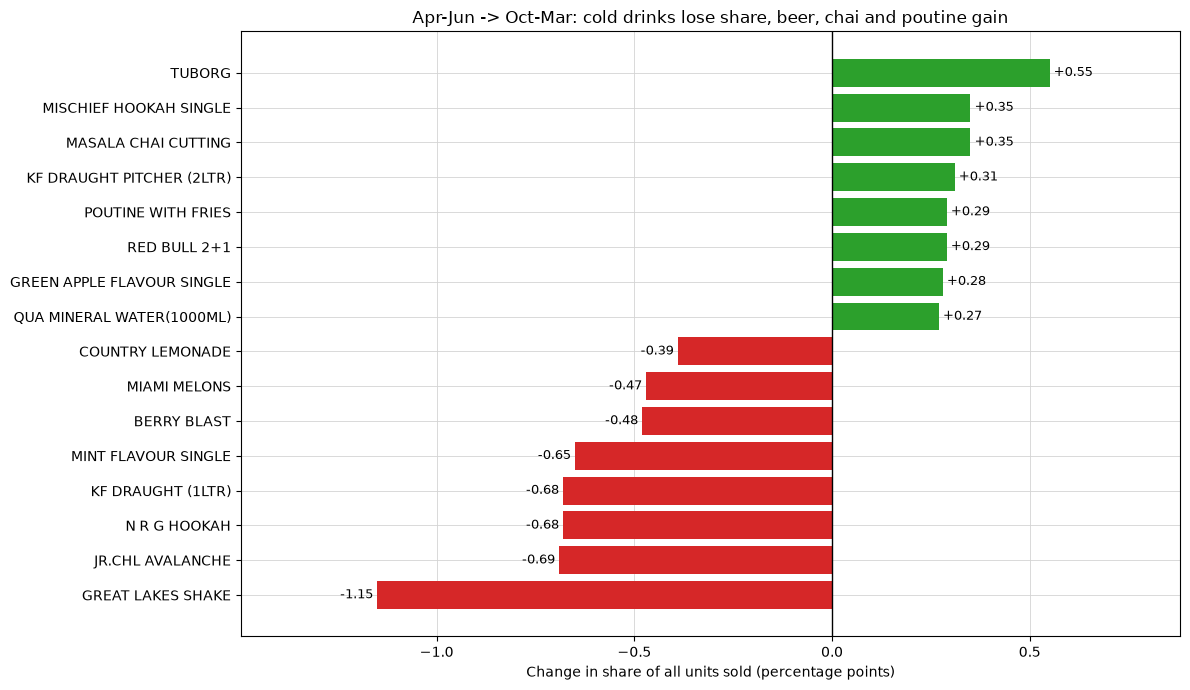

,Share Apr-Jun (%),Share Oct-Mar (%),Change (pp)
Item Desc,,,
TUBORG,1.49,2.05,0.55
MASALA CHAI CUTTING,1.51,1.86,0.35
MISCHIEF HOOKAH SINGLE,0.26,0.60,0.35
KF DRAUGHT PITCHER (2LTR),0.19,0.50,0.31
POUTINE WITH FRIES,2.10,2.38,0.29
RED BULL 2+1,0.51,0.79,0.29
GREEN APPLE FLAVOUR SINGLE,1.46,1.74,0.28
QUA MINERAL WATER(1000ML),2.14,2.41,0.27
GREAT LAKES SHAKE,4.47,3.31,-1.15


In [48]:
season_change = cat.season_changes(df_copy)
cat.plot_season_changes(season_change)
season_change

- The **top products are the same all year**: **Nirvana Hookah Single** is number 1 in 10 of the 12 months (the Great Lakes Shake leads in April 2010, Cappuccino in January 2011), followed by Cappuccino, Great Lakes Shake and Mint Flavour.
- The **Great Lakes Shake** is in the top 3 in most months, but it is the product that **loses the most share** in Oct-Mar compared to Apr-Jun, together with other cold products (Jr. Chill Avalanche, Berry Blast, Miami Melons, Country Lemonade).
- **Winter winners** are hot and "heavier" products: **masala chai**, poutine, and beer (**Tuborg**, KF pitcher).
- **KF Draught 1 litre loses share while the KF pitcher gains**: a possible effect of a price or menu change, a good candidate for Part 3.

<a id="step-6-5"></a>
#### Step 6.5 - Relationships
- **Price vs units sold**: do cheaper products sell more? Units are measured **per day on sale** (Step 6.2) and the one-week specials are left out, so new and short-lived products are compared fairly. We use the **Spearman** correlation because prices and units are very skewed (it compares ranks instead of values).
- **Categories over time**: do the categories rise and fall together from day to day?

<a id="step-6-5-1"></a>
##### Step 6.5.1 - Price vs units sold

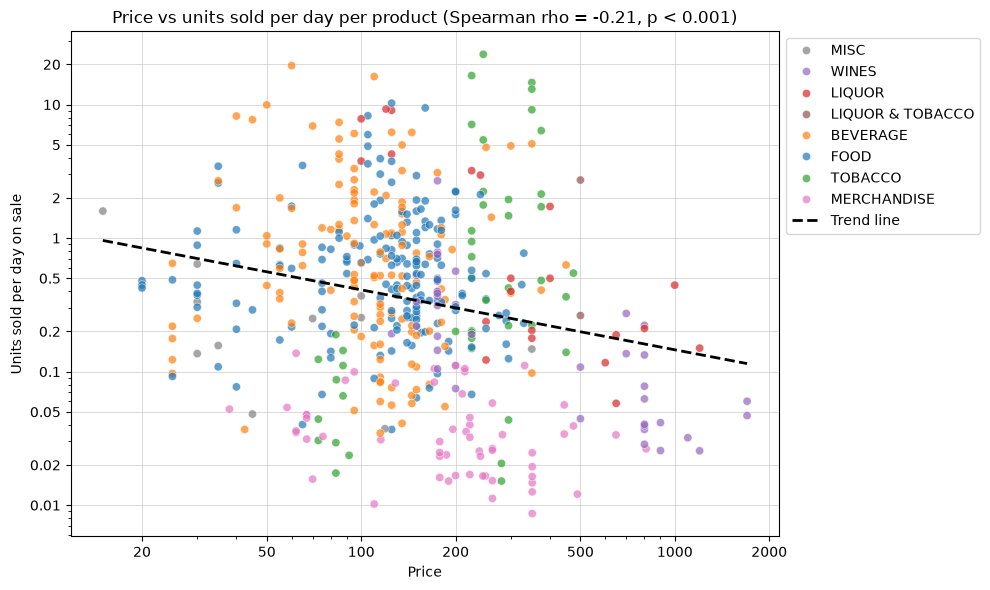

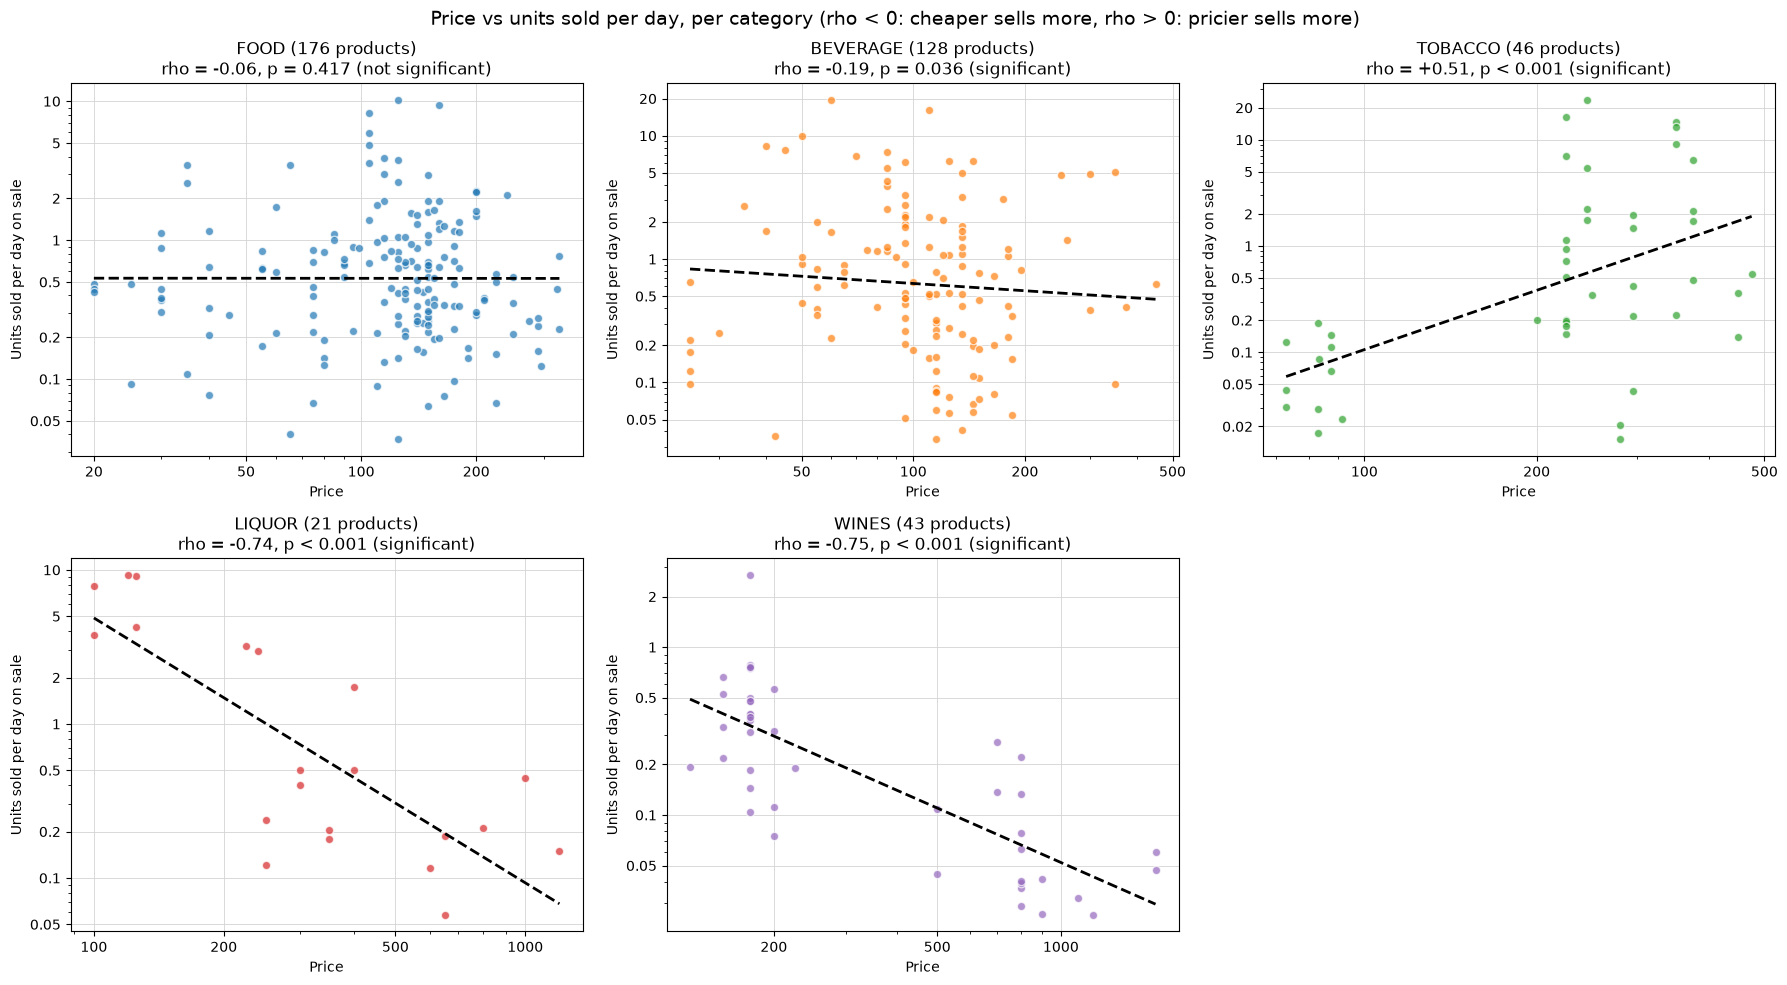

,Products,Spearman rho,p-value
All products,486,-0.21,0.000
FOOD,176,-0.06,0.417
BEVERAGE,128,-0.19,0.036
TOBACCO,46,0.51,0.000
LIQUOR,21,-0.74,0.000
WINES,43,-0.75,0.000


In [49]:
products = cat.price_vs_units(df_copy)
cat.plot_price_vs_units(products)
cat.plot_price_vs_units_by_category(products)
cat.price_units_correlation(products)

<a id="step-6-5-2"></a>
##### Step 6.5.2 - Categories over time

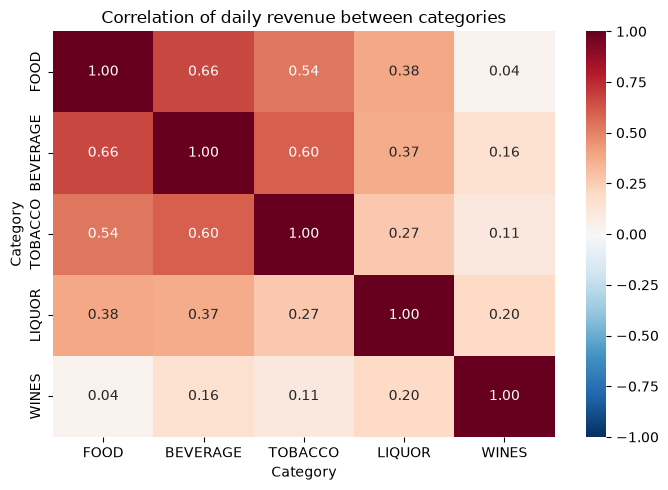

In [50]:
cat.plot_daily_category_correlation(df_copy)

- **Overall, cheaper products sell a bit more** (Spearman rho = -0.21), but that's mostly because categories have different price levels.
- **Within categories** the picture is different: for **liquor and wine** cheaper clearly sells more (rho -0.74 and -0.75), for **food** price doesn't matter (no significant relation), and for **tobacco the more expensive hookahs sell more** (rho +0.51): customers are willing to pay for premium hookahs.
- **Food, beverage and tobacco rise and fall together** from day to day (correlations 0.54-0.66): they are driven by the same thing, the number of visitors. **Liquor** follows less (0.27-0.38) and **wine** is almost independent (rare, irregular sales).

<a id="step-6-6"></a>
#### Step 6.6 - Anomalies
Things in the data that don't behave like normal sales, found during the previous steps.

<a id="step-6-6-1"></a>
##### Step 6.6.1 - Items sold for 0.01
Flagged in Step 3:

In [51]:
cat.free_items(df_copy)

,Date,Time,Bill Number,Item Desc,Quantity,Rate,Total
88182,2010-05-09,18:51:51,G0476259,MOTHERS DAY SPL,1,0.01,0.01
88183,2010-05-09,22:21:55,G0476303,MOTHERS DAY SPL,1,0.01,0.01
88184,2010-05-09,22:42:38,G0476311,MOTHERS DAY SPL,1,0.01,0.01
88185,2010-05-09,12:10:55,G0476201,MOTHERS DAY SPL,1,0.01,0.01
88186,2010-05-09,00:39:33,G0476338,MOTHERS DAY SPL,1,0.01,0.01


<a id="step-6-6-2"></a>
##### Step 6.6.2 - The biggest orders
Flagged as outliers in Step 4:

In [52]:
cat.biggest_orders(df_copy, df_orders)

,Date,Time,Unique_Items,Quantity,Total,Most expensive line
Bill Number,,,,,,
G0522713,2011-01-25,21:21:02,1,23,14231.25,PARTY CHARGES @ 500/-
G0481424,2010-06-11,21:51:46,15,64,11415.95,ASSORTED TAPAS (2)NONVEG
G0518491,2011-01-02,23:27:37,15,58,8985.96,CHEESE FONDUE
G0516596,2010-12-25,14:47:32,12,52,8602.71,LEMON ICED TEA
G0527570,2011-02-20,21:24:40,16,41,8111.84,LEMON ICED TEA


<a id="step-6-6-3"></a>
##### Step 6.6.3 - Two bill series
Bill numbers start with `G` or `N`. We compared both:

In [53]:
cat.bill_series(df_copy, df_orders)

,Orders,Avg_order_value,Avg_products,Share of orders,Alcohol share of revenue
Bill series,,,,,
G,63775,474.96,2.16,91%,0%
N,6207,405.22,1.14,9%,100%


<a id="step-6-6-4"></a>
##### Step 6.6.4 - Menu changes
While fixing the item names (Step 3) we saw names that stop being used in December and new names from January. We count, per month, how many products are sold for the first and the last time:

In [54]:
print("Days with the most new products in January 2011:")
print(cat.first_sale_dates(df_copy).to_string())
cat.menu_changes(df_copy)

Days with the most new products in January 2011:
Date
2011-01-07    18
2011-01-08    19
2011-01-09     9
2011-01-10     6
2011-01-11     5


,Products sold,New products,Products sold for the last time
Date,,,
Apr 10,303,0,20
May 10,293,36,11
Jun 10,315,39,18
Jul 10,315,26,18
Aug 10,305,14,14
Sep 10,298,12,22
Oct 10,281,8,9
Nov 10,281,6,5
Dec 10,318,22,50


<a id="step-6-6-5"></a>
##### Step 6.6.5 - Summary of the anomalies
| Anomaly | What we found | What we do with it |
|---|---|---|
| **Items at 0.01** | 5 lines of `MOTHERS DAY SPL` on 9 May 2010: a free gift added to bills | Keep: real event, no effect on revenue |
| **Biggest bill (14,231)** | `PARTY CHARGES @ 500/-` x 23 on 25 Jan 2011: a party booking. This explains the 25 Jan surprise in Step 5 | Keep, flag as special day (Step 7) |
| **Very large orders** (40-64 items) | Group orders on 11 Jun, Christmas Day, 2 Jan and 20 Feb | Keep: real sales, part of the order outliers in Step 4 |
| **Two bill series** | `N` bills (9% of orders) contain **only alcohol**, `G` bills **never** contain alcohol: the café bills alcohol separately | Important for Part 2: a beer and a hookah in the same visit end up on **two different bills** |
| **New menu in January 2011** | 37 new products on 7-8 January, 73 new products in January, while 125 products are sold for the last time in Dec-Jan | Flag old/new menu (Step 7), candidate for Part 3 |
| **December MISC spike** | New December products (sheeshas, KF draft mug, spirits) were booked as MISC | Fixed in Step 3 |
| **New Year's Eve** | ~250k, almost 3x a normal day (Step 5) | Flag as special day (Step 7) |

<a id="step-6-7"></a>
#### Step 6.7 - Key takeaways
1. **Hookah is the core business**: 45% of revenue from 23% of the units, the biggest earner in every part of the day, and premium hookahs sell better than cheap ones.
2. **Drinks bring people in, hookah brings in the money**: beverages are 41% of units but only 25% of revenue.
3. **Revenue is concentrated, but the menu tail is smaller than it looks**: 66 products make 80% of the revenue. Most products with low yearly sales were specials, new or retired. Of the 313 products on the 2011 menu, 78 sell less than once a week (0.9% of revenue): merchandise, slow wines and speciality-coffee variants that could be grouped.
4. **Alcohol is billed separately**, so baskets with alcohol and hookah/food are split over two bills. We must keep this in mind in Part 2.
5. **A new menu started on 7 January 2011**, and several big events (party booking, group orders, New Year's Eve) explain the biggest revenue surprises.

<a id="step-7"></a>
### Step 7 - Offensive Data Preparation & Feature Engineering
We turn what we learned in Steps 3-6 into new columns, so the next parts (market basket analysis and our own question) can use them directly. Every feature comes from a finding:

In [55]:
fe.FEATURES

,Level,What it is,Why we need it
Feature,,,
Hour,line + order,Hour of the order (0-23),Hourly cycle (Step 5)
Daypart,line + order,Late morning / Lunch / Afternoon / Evening / N...,Category mix changes through the day (Step 6)
Business day,line + order,"Date, but orders before 06h count for the prev...",A night out doesn't stop at midnight (Step 5)
Weekday,line + order,Weekday of the business day,Weekly cycle (Step 5)
Weekend,line + order,"True for Fri, Sat and Sun nights","Strongest nights (Step 5, test in Step 6)"
Special day,line + order,"Name of the holiday/event, or 'No'",Largest surprises in the decomposition (Step 5)
Menu,line + order,Old menu / New menu (from 7 Jan 2011),Menu change found in Step 6
Bill series,line + order,Main bill (G) / Alcohol bill (N),Alcohol is billed separately (Step 6)
Promo,line,Buy 1 get 1 / Multi-buy / Multi-pack / Combo /...,"Deals are only in the name, not in Discount (S..."


<a id="step-7-1"></a>
#### Step 7.1 - Promotion and base product
When we searched for duplicate item names in Step 3, many names looked almost identical but had a prefix or suffix like `1+1`, `B1G1` or `2+1`, e.g. `VLN CAB SAUV (GLS)` vs `1+1 VLN CAB SAUV (GLS)`, or `CARLSBERG` vs `CARLSBERG 2+1`. These are the **same base product sold as a deal**, at a different price.

We don't merge them with the normal product, because that would mix different prices and quantities. But we don't want to lose that information either: the dataset has a `Discount` column, and **promotions are not recorded there**. They only show up in the product name. So we add two columns:
- `Promo`: the type of deal, found from patterns in the name
- `Base product`: the name without the deal (`1+1 VLN CAB SAUV (GLS)` -> `VLN CAB SAUV (GLS)`), so a product can be compared with and without its deal

| Promo | Pattern in the name | Examples |
|---|---|---|
| **Buy 1 get 1** | starts with `1+1` or `B1G1` | `1+1 KF 1/2 LITER`, `B1G1 ZINZI RED (GLS)` |
| **Multi-buy** | `2+1`, `3+2`, ... | `CARLSBERG 2+1`, `RED BULL 3+2` |
| **Multi-pack** | starts with 2-9 followed by the product | `3 RED BULL`, `2 AXE TWIST` |
| **Combo** | two products joined by ` + ` | `WAFFLES + BEVERAGE`, `2 DOM BEER + 1SPL SHEESHA` |

Names that start with a number but are not a deal are left out on purpose: `4 SEASONS ...` and `2 OCEAN PINOTAGE` are wine brands, `3COURSE ... MEAL` is a set menu and `1 AXE TWIST` is a single item.

In [56]:
df_copy = fe.add_line_features(df_copy)
fe.promo_summary(df_copy)

,Products,Units,Revenue,Lines_with_discount,Revenue share
Promo,,,,,
No promo,535,161323,"32,062,776",262,97.7%
Multi-buy,8,1378,"455,657",3,1.4%
Buy 1 get 1,22,363,"89,936",1,0.3%
Multi-pack,4,327,"123,379",2,0.4%
Combo,8,128,"74,148",0,0.2%


In [57]:
# Which products are on promotion, and what is their base product?
fe.promo_products(df_copy)

Base_product  Units
Promo       Item Desc                                                       
Buy 1 get 1 1+1 BTL4 SEASON WHITE                   BTL4 SEASON WHITE      2
            1+1 GLS 4SEASON RED                       GLS 4SEASON RED     11
            1+1 GLS 4SEASONS WHITE                 GLS 4SEASONS WHITE     13
            1+1 KF 1 LITER                          KF DRAUGHT (1LTR)     48
            1+1 KF 1/2 LITER                      KF DRAUGHT (1/2LTR)    136
            1+1 KF 2 LITER                  KF DRAUGHT PITCHER (2LTR)      7
            1+1 VLN CAB SAUV (BTL)                 VLN CAB SAUV (BTL)      1
            1+1 VLN CAB SAUV (GLS)                 VLN CAB SAUV (GLS)     12
            1+1 VLN CAB SAUV CLASIQ (BTL)   VLN CAB SAUV CLASIQ (BTL)      2
            1+1 VLN CAB SAUV CLASIQ (GLS)   VLN CAB SAUV CLASIQ (GLS)     22
            1+1 VLN CHENIN BLANC (GLS)         VLN CHENIN BLANC (GLS)     21
            1+1 VLN SAUV BLANC (BTL)             VLN SAUV BLANC (BTL)      1
            1+1 VLN SAUV BLANC (GLS)             VLN SAUV BLANC (GLS)     10
            1+1 WINE BOTTLE                               WINE BOTTLE      2
            1+1 WINE GLASS                                 WINE GLASS     43
            B1G1 4SEASON CLAS SAUV(BTL)      4 SEASONS CLAS SAUV(BTL)      1
            B1G1 4SEASON CLAS SAUV(GLS)       4 SEASONS CLAS SAUV(GLS      1
            B1G1 4SEASON CLAS SYRAH(GLS)    4 SEASONS CLAS SYRAH(GLS)      2
            B1G1 ZINZI RED (BTL)                      ZINZI RED (BTL)      3
            B1G1 ZINZI RED (GLS)                      ZINZI RED (GLS)     12
            B1G1 ZINZI WHITE (BTL)                  ZINZI WHITE (BTL)      3
            B1G1 ZINZI WHITE (GLS)                  ZINZI WHITE (GLS)     10
Combo       2 DOM BEER + 1PREM SHEESHA     2 DOM BEER + 1PREM SHEESHA      2
            2 DOM BEER + 1SPL SHEESHA       2 DOM BEER + 1SPL SHEESHA     10
            2 MUFFINS + BEVERAGE                 2 MUFFINS + BEVERAGE      3
            4 DOM BEER + 1SPL SHEESHA       4 DOM BEER + 1SPL SHEESHA      2
            REDBULL HOOKAH + 2REDBULL       REDBULL HOOKAH + 2REDBULL     99
            SCRAMBLED EGGS + BEVERAGE       SCRAMBLED EGGS + BEVERAGE      7
            SUNNY SIDEUP + BEVERAGE           SUNNY SIDEUP + BEVERAGE      2
            WAFFLES + BEVERAGE                     WAFFLES + BEVERAGE      3
Multi-buy   CARLSBERG 2+1                                   CARLSBERG     21
            HOEGAARDEN GLS (2+1)                     HOEGAARDEN (GLS)      1
            HOEGAARDEN LTR MUGS (2+1)        HOEGAARDEN MUG (1 LITRE)      1
            RED BULL 2+1                        RED BULL ENERGY DRINK   1225
            RED BULL 3+2                        RED BULL ENERGY DRINK    104
            SCHNEIDER 2+1                            SCHNEIDER WEISSE      2
            STELLA 1LTR 2+1                 STELLA ARTOIS MUG (1 LTR)      5
            TUBORG 2+1                                         TUBORG     19
Multi-pack  2 AXE TWIST                                     AXE TWIST      1
            2 RED BULL                          RED BULL ENERGY DRINK     22
            3 RED BULL                          RED BULL ENERGY DRINK    270
            5 RED BULL                          RED BULL ENERGY DRINK     34

What the promo column tells us:
- **Promotions are a small part of the business**: 42 products on a deal, ~743k in revenue, only **~2.3% of total revenue**.
- **The `Discount` column doesn't capture them**: only 6 of the ~270 discounted lines are promo items. Without this column, promotions would be invisible in the analysis.
- **Red Bull deals are the most used promotion by far**: `RED BULL 2+1` alone sold 1,225 units. It was used until early January 2011, and from February `3 RED BULL` (and `2`/`5 RED BULL`) appear instead. This looks like the same Red Bull deal under a new name and price (250 vs 300), probably part of the new menu.
- **Beer and wine deals were short campaigns**: the Kingfisher `1+1` deals only ran from 12 to 26 September 2010, which explains the spike of promo sales in September. The wine `1+1` deals ran in June-July.
- **Base product**: most deals simply add a prefix or suffix to the regular name. A few beer and Red Bull deals use a short name (`KF 1/2 LITER`, `RED BULL`), so we map those to their regular product (`KF DRAUGHT (1/2LTR)`, `RED BULL ENERGY DRINK`). Deals without a regular version (e.g. `1+1 WINE GLASS`) keep their own name.
- In Part 3 this column lets us compare the same product with and without its deal.

<a id="step-7-2"></a>
#### Step 7.2 - Time, drink and bill features
- `Business day`, `Weekday`, `Weekend`: orders before 06h count for the previous evening, so Friday night stays Friday night (Step 5)
- `Special day`: the holidays and events that stood out in Step 5 and 6 (New Year's Eve, Valentine's Day, the party booking, ...)
- `Menu`: old menu / new menu from 7 January 2011 (Step 6)
- `Drink type`: hot / cold / other drink, or not a drink (Step 5)
- `Bill series`: main bill or alcohol bill (Step 6)

In [58]:
feature_cols = ["Date", "Time", "Item Desc", "Category", "Daypart", "Business day", "Weekday", "Weekend",
                "Special day", "Menu", "Drink type", "Bill series", "Promo", "Base product"]
df_copy[feature_cols].sample(8, random_state=1)

,Date,Time,Item Desc,Category,Daypart,Business day,Weekday,Weekend,Special day,Menu,Drink type,Bill series,Promo,Base product
107593,2010-11-23,13:24:24,SAMBUCA,TOBACCO,Lunch (12-15h),2010-11-23,Tue,False,No,Old menu,Not a drink,Main bill,No promo,SAMBUCA
27581,2010-12-08,20:20:26,POUTINE WITH FRIES,FOOD,Evening (19-23h),2010-12-08,Wed,False,No,Old menu,Not a drink,Main bill,No promo,POUTINE WITH FRIES
49068,2011-03-06,20:33:06,CHICKEN SAUSAGE,FOOD,Evening (19-23h),2011-03-06,Sun,True,No,New menu,Not a drink,Main bill,No promo,CHICKEN SAUSAGE
8473,2010-07-03,17:30:41,ULTIMATE HOT CHOCOLATE,BEVERAGE,Afternoon (15-19h),2010-07-03,Sat,True,No,Old menu,Hot,Main bill,No promo,ULTIMATE HOT CHOCOLATE
116216,2010-11-30,15:56:29,RED BULL 2+1,BEVERAGE,Afternoon (15-19h),2010-11-30,Tue,False,No,Old menu,Other,Main bill,Multi-buy,RED BULL ENERGY DRINK
72594,2010-06-16,23:29:17,COTTAGE CHEESE PANINI,FOOD,Night (23-03h),2010-06-16,Wed,False,No,Old menu,Not a drink,Main bill,No promo,COTTAGE CHEESE PANINI
24178,2010-12-07,18:31:25,GREAT LAKES SHAKE,BEVERAGE,Afternoon (15-19h),2010-12-07,Tue,False,No,Old menu,Cold,Main bill,No promo,GREAT LAKES SHAKE
17257,2010-12-05,00:29:23,MASALA CHAI CUTTING,BEVERAGE,Night (23-03h),2010-12-04,Sat,True,No,Old menu,Hot,Main bill,No promo,MASALA CHAI CUTTING


<a id="step-7-3"></a>
#### Step 7.3 - Order-level features
For the market basket analysis (Part 2) we need one row per order with its size, value, timing and which categories it contains.

In [59]:
order_features = fe.build_order_features(df_copy)
order_features.head()

,Business day,Weekday,Weekend,Daypart,Hour,Special day,Menu,Bill series,Products,Units,Order_value,Has FOOD,Has BEVERAGE,Has TOBACCO,Has LIQUOR,Has WINES,Has promo
Bill Number,,,,,,,,,,,,,,,,,
G0470109,2010-04-01,Thu,False,Late morning (10-12h),11,No,Old menu,Main bill,1,1,117.56,False,True,False,False,False,False
G0470110,2010-04-01,Thu,False,Lunch (12-15h),12,No,Old menu,Main bill,1,1,323.40,False,False,True,False,False,False
G0470111,2010-04-01,Thu,False,Lunch (12-15h),12,No,Old menu,Main bill,4,4,495.00,True,True,False,False,False,False
G0470112,2010-04-01,Thu,False,Lunch (12-15h),12,No,Old menu,Main bill,2,2,385.28,False,True,True,False,False,False
G0470113,2010-04-01,Thu,False,Lunch (12-15h),12,No,Old menu,Main bill,1,1,323.40,False,False,True,False,False,False


In [60]:
# Share of orders containing each category, and orders with more than one product
has_cols = [c for c in order_features if c.startswith("Has ")]
summary = order_features[has_cols].mean().map("{:.1%}".format).to_frame("Share of orders")
summary.loc["More than one product"] = f"{(order_features['Products'] > 1).mean():.1%}"
summary

,Share of orders
Has FOOD,37.8%
Has BEVERAGE,53.4%
Has TOBACCO,48.4%
Has LIQUOR,8.0%
Has WINES,1.2%
Has promo,2.9%
More than one product,54.4%


- **54% of the orders contain more than one product**, so about 38,000 orders can be used for the market basket analysis in Part 2.
- **Beverage (53%) and tobacco (48%) are the most common** in an order, food is in 38%.
- **Only 13% of the alcohol bills have more than one product** (58% of the main bills), because alcohol is billed on its own. In Part 2 we have to decide how to handle this, e.g. analyse the main bills and the alcohol bills separately.
- Promotions are in only 2.9% of the orders.

<a id="step-7-4"></a>
#### Step 7.4 - Saving the cleaned data
We save the result of Steps 3-7 in the `data/` folder, so the next parts can start from the cleaned data instead of the raw file:
- `cafe_clean_lines.csv`: one row per item in an order, with all fixes from Step 3 and the new columns from Step 7
- `cafe_clean_orders.csv`: one row per order (bill), with its size, value, timing and which categories it contains: the starting point for the market basket analysis (Part 2)

In [61]:
df_copy.to_csv("data/cafe_clean_lines.csv", index=False)
order_features.to_csv("data/cafe_clean_orders.csv")   # the index is the bill number
print(f"cafe_clean_lines.csv:  {df_copy.shape[0]:,} rows x {df_copy.shape[1]} columns")
print(f"cafe_clean_orders.csv: {order_features.shape[0]:,} rows x {order_features.shape[1] + 1} columns")

cafe_clean_lines.csv:  145,052 rows x 21 columns
cafe_clean_orders.csv: 69,982 rows x 18 columns


<a id="part-2"></a>
## Part 2 - Market Basket Analysis
Which products are bought together, and which pairs would make good **combo deals**? We look for product pairs that appear on the same bill more often than chance, for the whole day and for each part of the day.

The calculations live in [apriori_market_basket_analysis_daypart_overview.py](scripts/apriori_market_basket_analysis_daypart_overview.py) (imported as `mba`), so here we only show the results and what they mean.

<a id="p2-step-1"></a>
### Step 1 - Dataset Selection and Feature Engineering for MBA
Part 1 saved two cleaned datasets (Step 7.4). Both cover the same 69,982 bills, but at a different level:

| Criterion | `cafe_clean_lines.csv` (selected) | `cafe_clean_orders.csv` (not selected) |
|---|---|---|
| **Granularity** | Line-item level (one row per item in a bill) | Order level (one row per bill) |
| **Product detail** | Keeps the product names (`Item Desc`, `Base product`), prices (`Rate`) and discounts | Only bill totals (`Products`, `Units`, `Order_value`) and category flags (`Has FOOD`, ...) |
| **Suitability for combo deals** | High: shows exactly which products are on the same bill | Low: only shows which *categories* are on the same bill |

The features from Part 1 are made for the EDA, so we add four transformations for the basket analysis:
1. **Group on `Base product`** (Step 7.1), so a product and its deal version count as the same product.
2. **Binary presence per bill**: a product counts once per bill (1/0), so ordering 3 of the same item doesn't distort the pair probabilities.
3. **Remove noise**: `ADD ON S` and `MERCHANDISE` are not things anyone would bundle.
4. **Split by `Daypart`** (Step 6.3), because what people order changes a lot through the day.

In [62]:
mba_lines = mba.load_mba_lines("data/cafe_clean_lines.csv")   # removes ADD ON S and MERCHANDISE
products_per_bill = mba_lines.groupby("Bill Number")["Base product"].nunique()
print(f"Lines used for MBA: {len(mba_lines):,}")
print(f"Bills:              {mba_lines['Bill Number'].nunique():,}")
print(f"Bills with only one product: {(products_per_bill == 1).mean():.1%}")

Lines used for MBA: 144,226
Bills:              69,663
Bills with only one product: 45.5%


<a id="p2-step-2"></a>
### Step 2 - Algorithm Selection and Metrics
We use the **Apriori** algorithm. It uses the **Apriori principle**: if a single product is not frequent enough (below `min_support`), no pair containing it can be frequent either, so those pairs are pruned early. The steps are: frequent single products -> candidate pairs -> association rules.

- **Why Apriori**: the steps are transparent and easy to explain, and with ~70k bills it is fast enough to tune the thresholds by hand.
- **Alternatives**: *FP-Growth* builds a prefix tree and skips candidate generation, which is faster on very large data with very low thresholds, but harder to follow step by step. *ECLAT* intersects lists of bill IDs and works best on dense data, not on small café bills.

For a pair of products A (the **anchor**, the product people come for) and B (the **add-on**):

| Metric | Formula | Meaning |
|---|---|---|
| **Support (A, B)** | Bills with A and B / all bills | How common the pair is. Filters out rare coincidences |
| **Confidence (A -> B)** | Bills with A and B / bills with A | Out of the bills with A, how many also have B. The direction matters |
| **Lift (A, B)** | Support(A, B) / (Support(A) x Support(B)) | How much more often they are bought together than by chance. > 1 positive, = 1 independent, < 1 negative |

In the code the product that sells most of the two is the anchor and the other is the add-on.

<a id="p2-step-3"></a>
### Step 3 - Threshold Calibration and Overall Rules
The menu has hundreds of products and almost half of the bills contain only one product, so the support of any pair is naturally low. With `min_support = 1%` no pair is left, and with very low thresholds we get noise. We use:
- **Whole year**: `min_support = 0.3%` (at least 25 bills) and `min_lift = 1.15`
- **Per daypart**: `min_support = 0.4%` (at least 10 bills) and `min_lift = 1.15`

In [63]:
mba_overall = mba.run_overall(mba_lines)
print(f"Rules for the whole year: {len(mba_overall)}")
mba_overall[["anchor_product", "addon_product", "cat_a", "cat_b", "bills_together", "support_pct",
             "conf_a_to_b_pct", "conf_b_to_a_pct", "lift", "sum_rate"]]

Rules for the whole year: 20


,anchor_product,addon_product,cat_a,cat_b,bills_together,support_pct,conf_a_to_b_pct,conf_b_to_a_pct,lift,sum_rate
0,SAMBUCA,RED BULL ENERGY DRINK,BEVERAGE,TOBACCO,612,0.88,18.2,13.8,2.86,559.24
1,RED BULL ENERGY DRINK,CALCUTTA MINT,TOBACCO,BEVERAGE,406,0.58,12.3,12.1,2.54,566.74
2,RED BULL ENERGY DRINK,N R G HOOKAH,TOBACCO,BEVERAGE,276,0.40,12.3,8.2,2.54,585.54
3,POUTINE WITH FRIES,B.M.T. PANINI,FOOD,FOOD,266,0.38,10.2,7.8,2.08,230.24
4,QUA MINERAL WATER(1000ML),B.M.T. PANINI,FOOD,BEVERAGE,257,0.37,9.9,7.7,2.07,155.00
5,SAMBUCA,B.M.T. PANINI,FOOD,TOBACCO,328,0.47,12.6,7.4,1.98,469.61
6,RED BULL ENERGY DRINK,B.M.T. PANINI,FOOD,BEVERAGE,235,0.34,9.0,7.0,1.87,299.64
7,CAPPUCCINO,CAFFE LATTE,BEVERAGE,BEVERAGE,297,0.43,14.2,5.4,1.81,134.24
8,CALCUTTA MINT,B.M.T. PANINI,FOOD,TOBACCO,211,0.30,8.1,6.4,1.71,477.10
9,POUTINE WITH FRIES,RED BULL ENERGY DRINK,FOOD,BEVERAGE,267,0.38,7.8,7.9,1.62,319.88


- **Red Bull + Sambuca is the strongest pair of the year**: they are on 612 bills together (support 0.88%). Of the bills with a Red Bull, 18.2% also have a Sambuca hookah (and 13.8% the other way around), giving a **lift of 2.86**: almost 3x more often than by chance.
- **Red Bull goes with hookah**: the top 3 pairs are all Red Bull with a hookah flavour (Sambuca, Calcutta Mint, N R G).
- The **B.M.T. panini** pairs with many products (poutine, water, hookah, Red Bull, shakes): it's the most "shareable" food item.
- All rules have a support below 1%: product pairs are rare, so even the best pairs are a small part of all bills.

<a id="p2-step-4"></a>
### Step 4 - Combo Deals per Daypart
One combo for the whole day would not fit, because what people order changes through the day (Step 6.3). We run Apriori on each daypart separately and rank the pairs by lift: **rank 1 is the best deal** of that daypart, the next two are runners-up.

In [64]:
mba_daypart = mba.run_by_daypart(mba_lines)
print(f"Rules per daypart: {len(mba_daypart)}")
print(mba_daypart.groupby("daypart", sort=False).size().to_string())
mba.top_per_daypart(mba_daypart, n=3)

Rules per daypart: 67
daypart
Late morning (10-12h)     7
Lunch (12-15h)           10
Afternoon (15-19h)       12
Evening (19-23h)         16
Night (23-03h)           22


,daypart,recommendation_tag,anchor_product,addon_product,bills_together,support_pct,conf_anchor_to_addon_pct,lift,sum_rate
0,Late morning (10-12h),BEST DEAL,QUA MINERAL WATER(1000ML),HASH BROWN OMELETTE,10,0.59,9.0,5.08,215.00
1,Late morning (10-12h),Runner-up,QUA MINERAL WATER(1000ML),SCRAMBLED EGGS,19,1.12,17.1,4.67,148.95
2,Late morning (10-12h),Runner-up,QUA MINERAL WATER(1000ML),SPANISH OMELETTE BREAKFAST,12,0.71,10.8,3.81,180.52
3,Lunch (12-15h),BEST DEAL,B.M.T. PANINI,ADD FRIES,39,0.42,10.7,6.58,140.00
4,Lunch (12-15h),Runner-up,B.M.T. PANINI,PHILLYCREAM CHEESE &CHILLY PAN,41,0.45,11.2,3.40,210.00
5,Lunch (12-15h),Runner-up,SAMBUCA,RED BULL ENERGY DRINK,50,0.54,11.7,3.19,550.59
6,Afternoon (15-19h),BEST DEAL,SAMBUCA,RED BULL ENERGY DRINK,191,0.89,14.0,2.85,560.33
7,Afternoon (15-19h),Runner-up,CALCUTTA MINT,RED BULL ENERGY DRINK,143,0.67,12.3,2.50,564.72
8,Afternoon (15-19h),Runner-up,RED BULL ENERGY DRINK,N R G HOOKAH,99,0.46,9.4,2.42,587.60
9,Evening (19-23h),BEST DEAL,SAMBUCA,RED BULL ENERGY DRINK,209,0.88,13.8,2.98,558.27


- **Late morning (10-12h)**: a **breakfast bundle** of eggs or an omelette with a 1L bottle of mineral water. The best pair by lift (hash brown omelette) is based on only 10 bills, so scrambled eggs + water (19 bills, lift 4.67) is the safer choice.
- **Lunch (12-15h)**: **B.M.T. panini + fries** has the highest lift of all dayparts (6.58): a meal upgrade.
- **Afternoon (15-19h) and evening (19-23h)**: **Red Bull + Sambuca hookah** is the best deal, with the most bills of all pairs (191 and 209). Red Bull with other hookah flavours (Calcutta Mint, N R G) are the runners-up.
- **Night (23-03h)**: **Nirvana hookah + a small bottle of water** (lift 3.25), a late-night hydration bundle. Red Bull + Sambuca is still among the top pairs.

<a id="p2-step-5"></a>
### Step 5 - Exporting the rules
The full rule tables are saved in the `outputs/` folder, so they can be opened outside the notebook.

In [65]:
for path in mba.save_results(mba_overall, mba_daypart, out_dir="outputs"):
    print(path)

outputs\apriori_combideals_overall_en.csv
outputs\apriori_combideals_per_daypart_en.csv


<a id="p2-step-6"></a>
### Step 6 - Recommendations and Limitations
**Recommended combo deal per daypart:**

| Daypart | Combo deal | Idea |
|---|---|---|
| Late morning (10-12h) | Scrambled eggs + Qua mineral water (1L) | Breakfast bundle |
| Lunch (12-15h) | B.M.T. panini + fries | Lunch meal upgrade |
| Afternoon (15-19h) | Red Bull + Sambuca hookah | Afternoon lounge bundle |
| Evening (19-23h) | Red Bull + Sambuca hookah | Peak evening hookah + energy |
| Night (23-03h) | Nirvana hookah single + Qua mineral water (500ml) | Late-night hydration bundle |

**Limitations:**
- **No cost data**: we know the selling price, not the margin, so the discount of a bundle must be checked against the costs first.
- **Correlation is not causation**: a high lift means the products are on the same bill (often a table of several people), not that a discount on A will make people buy B.
- **Alcohol is on separate bills** (Part 1, Step 6.6): pairs of alcohol with food or hookah can't be found in this data.
- **Old data**: April 2010 - March 2011. The menu and prices must be checked before launching a deal.

<a id="part-3"></a>
## Part 3 - Do Red Bull Promotions Increase Revenue?
In Part 1 (Step 7.1) we found that **Red Bull deals are the café's most used promotion**: `RED BULL 2+1` until early January 2011, then `2`, `3` and `5 RED BULL` multi-packs, plus a few combos. At the same time the price of a regular Red Bull went up with the new menu, and traffic is higher at the weekend (Step 5). So a simple "promo days earn more" comparison could be driven by busy days or by the higher price.

**Question: do Red Bull promotions increase daily Red Bull revenue once store traffic, weekend patterns and the menu price increase are accounted for?**

The calculations live in [red_bull_promotion_analysis.py](scripts/red_bull_promotion_analysis.py) (imported as `rba`), so here we only show the results and what they mean.

<a id="p3-step-1"></a>
### Step 1 - Daily Red Bull dataset
We start from `cafe_clean_lines.csv` (Part 1, Step 7.4), keep every line whose name or base product contains "Red Bull", and roll the data up to **one row per business day** (orders before 06h count for the previous evening, Step 7.2):

| Variable | Role | Definition |
|---|---|---|
| `rb_rev` | Outcome (Y) | Total daily Red Bull revenue |
| `promo_share` | Predictor (X1) | Share of the day's Red Bull units sold on a promotion (0 to 1) |
| `post_hike` | Control (X2) | 1 from 30 Dec 2010 onwards (new Red Bull price), 0 before |
| `weekend_num` | Control (X3) | 1 on Friday, Saturday and Sunday business days |
| `total_bills` | Control (X4) | Number of bills in the whole café that day: store traffic |

We use the **share** of promo units instead of a yes/no "promo day" flag, because on most days (275 of 366) at least some Red Bull is sold on a deal: the share tells us *how much* of the day's Red Bull was sold that way.

In [73]:
rb_lines_all, rb_lines, rb_daily = rba.build_daily_table("data/cafe_clean_lines.csv")
rba.data_summary(rb_lines_all, rb_lines, rb_daily)

,Value
Lines in cafe_clean_lines.csv,"145,052"
Business days,366 (2010-03-31 to 2011-03-31)
Red Bull lines,"3,610"
Red Bull units,"4,123"
Red Bull revenue,"1,046,680.46"


<a id="p3-step-2"></a>
### Step 2 - Key operational findings
Before modelling, three facts about Red Bull sales that the model has to take into account.

In [74]:
rba.price_shift(rb_lines)

,Unit price (Rate)
Before 30 Dec 2010,125.0
From 30 Dec 2010,150.0


**Price shift**: a regular Red Bull Energy Drink cost **125 before 30 Dec 2010 and 150 from then on** (the new menu). That's why the model has a `post_hike` control.

In [75]:
rba.year_end_spike(rb_lines, rb_daily)

,Red Bull revenue,Promo share,RED BULL SHEESHA units,RED BULL SHEESHA revenue
Business day,,,,
2010-12-30,38071.71,4.9%,53.0,31482.0
2010-12-31,33536.26,4.5%,50.0,29700.0
2011-03-30,13543.55,83.8%,0.0,0.0


**Year-end spike**: on 30 and 31 December daily Red Bull revenue reached ~38k and ~34k, more than 10x a normal day. Most of it (~31k and ~30k) comes from **`RED BULL SHEESHA`**, a hookah flavour at 450 sold over New Year's Eve, not from a promotion. These two days fall in the `post_hike` period and are checked separately in Step 5.

In [76]:
display(rba.promo_mix(rb_lines))
rba.revenue_by_share_bin(rb_daily)

,Units,Revenue,Share of units,Share of revenue
Promo,,,,
No promo,2369,434198.12,57.5,41.5
Multi-buy,1329,427203.96,32.2,40.8
Multi-pack,326,123205.38,7.9,11.8
Combo,99,62073.00,2.4,5.9


,Days,Mean daily Red Bull revenue
promo_share,,
0%,91,1678.13
1-50%,112,3120.45
> 50%,163,3340.37


**Promotion mix**: promo lines (multi-buy, multi-pack and combo) are **42.5% of Red Bull units but 58.5% of Red Bull revenue**, because a deal line sells several cans at a higher line price. The 91 days without any promo sales average ~1.7k of Red Bull revenue, against ~3.1k on days with up to half of the units on promo and ~3.3k when more than half is on promo. This is the raw comparison; the regressions below check whether it survives the controls.

<a id="p3-step-3"></a>
### Step 3 - Simple linear regression
As a baseline we fit one line predicting daily Red Bull revenue from the promo share alone, on all 366 business days. We use **HC1 robust standard errors**, because the spread of daily revenue is not constant (busier days vary more, Step 5.2).

,Coefficient,HC1 std err,HC1 p-value
const,2209.7708,386.6158,0.0000
promo_share,1533.6706,631.5465,0.0152


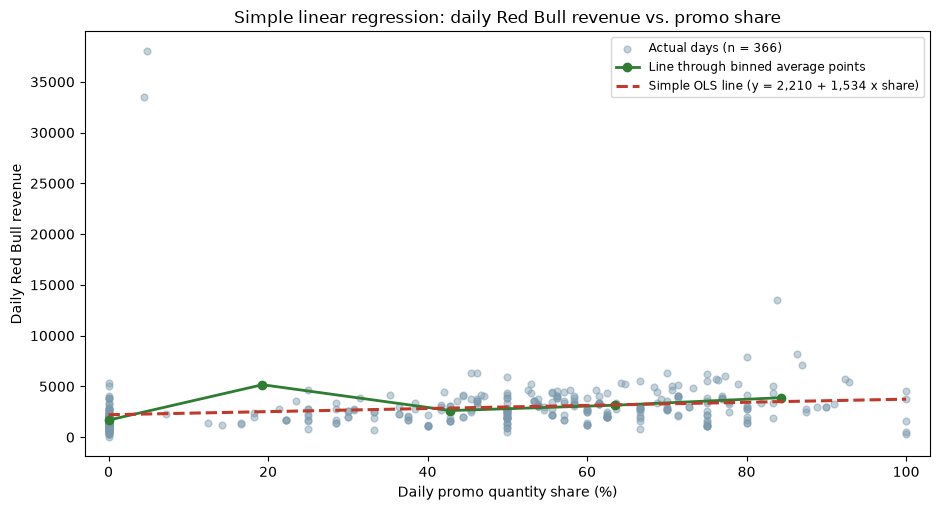

In [77]:
rb_simple, rb_multi = rba.fit_models(rb_daily)
display(rba.coef_table(rb_simple))
fig = rba.plot_simple_regression(rb_daily, rb_simple)

- Going from **0% to 100% promo share** goes together with **+1,534 daily Red Bull revenue** (p = 0.015), i.e. about +153 per 10 percentage points.
- But the model explains only **2.5% of the day-to-day variation** (R² = 0.025): the promo share alone says little about how much Red Bull a day sells. Other factors are missing, so we add them in Step 4.

<a id="p3-step-4"></a>
### Step 4 - Multiple linear regression
We keep the promo share as the main predictor and add the three controls: the price hike, the weekend and the store traffic. The second chart shows the **partial effect** of the promo share: daily revenue with the effect of the controls removed.

,Coefficient,HC1 std err,HC1 p-value
const,-4801.5913,3333.2160,0.1497
promo_share,1744.1206,536.7296,0.0012
post_hike,1219.8667,405.5918,0.0026
weekend_num,-114.5735,514.5234,0.8238
total_bills,34.8541,19.3857,0.0722


,Simple regression (k = 1),Multiple regression (k = 4)
n,366,366
k (predictors),1,4
SST,"2,999,710,577.62","2,999,710,577.62"
SSR,"74,584,498.73","538,105,328.36"
SSE,"2,925,126,078.89","2,461,605,249.26"
R^2,0.0249,0.1794
Adjusted R^2,0.0222,0.1703


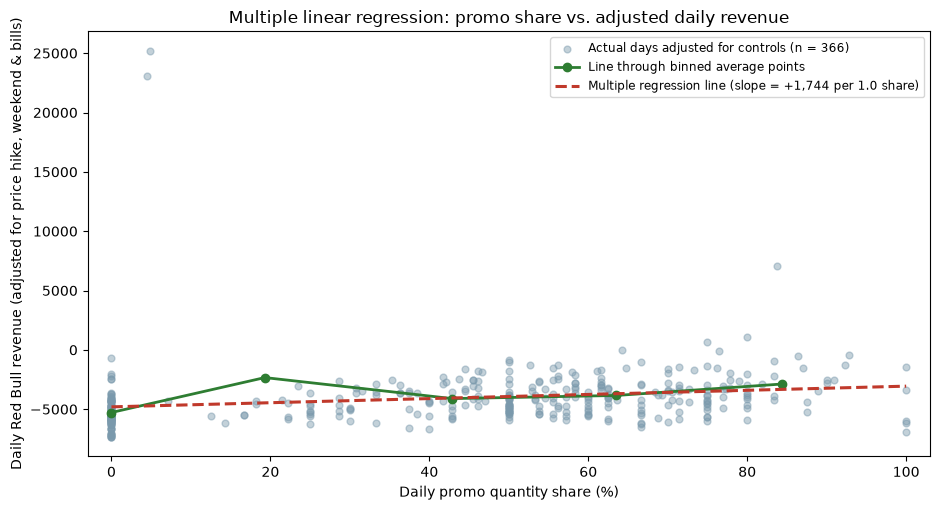

In [78]:
display(rba.coef_table(rb_multi))
display(rba.fit_stats_table(rb_simple, rb_multi))
fig = rba.plot_multiple_regression(rb_daily, rb_multi)

With the controls held fixed:
- **Promo share stays positive and becomes stronger**: from 0% to 100% promo share goes together with **+1,744 daily Red Bull revenue** (p = 0.001), about **+174 per 10 percentage points**.
- **Price hike**: days from 30 Dec 2010 bring in **~1,220 more** Red Bull revenue (p = 0.003), the effect of the higher price.
- **Weekend**: no separate effect (p = 0.82) once the number of bills is in the model. Weekends matter through traffic, not on their own.
- **Store traffic**: each extra bill in the café adds ~35 of Red Bull revenue, but only at the 10% level (p = 0.07).
- **Fit**: adjusted R² rises from 0.022 to **0.170**: the controls explain much more, but **83% of the day-to-day variation is still unexplained**.

<a id="p3-step-5"></a>
### Step 5 - Sensitivity check: without the year-end spike
The two `RED BULL SHEESHA` days (Step 2) are extreme values that are not caused by promotions. We refit the multiple model without them to check that they don't drive the result.

In [79]:
rba.sensitivity_without_year_end(rb_daily)

,Days,promo_share coefficient,HC1 p-value,R^2,Adjusted R^2
All days,366.0,1744.1206,0.0012,0.1794,0.1703
Without 30-31 Dec 2010,364.0,2423.1587,0.0000,0.2974,0.2896


Without 30-31 December the promo effect gets **stronger (+2,423, p < 0.001)** and the model fits much better (R² 0.30). The conclusion doesn't depend on the year-end spike: if anything, those two days hide part of the promo effect.

<a id="p3-step-6"></a>
### Step 6 - Conclusions and limitations
**Conclusions**
- **Promotions go together with higher daily Red Bull revenue**, also after controlling for the price hike, weekends and store traffic: about **+174 per 10 percentage points** of promo share (+1,744 from 0% to 100%, p = 0.001).
- **Multi-buy and multi-pack deals bring in most of the promo revenue** (40.8% and 11.8% of Red Bull revenue), and promo lines make 58.5% of Red Bull revenue overall.
- **Recommendation**: keep the multi-buy and multi-pack Red Bull deals, and pair them with hookah, where Part 2 found the strongest Red Bull pairs.

**Limitations**
| Limitation | Why it matters |
|---|---|
| **Association, not causation** | This is observational data, not a controlled experiment. Days with more promo sales may also be days when customers wanted more Red Bull anyway |
| **Line price vs. volume** | A deal line carries a higher price than a single can, so part of the extra revenue is a bigger ticket per order, not necessarily more cans |
| **Most variation unexplained** | 83% of the day-to-day swings are not explained by the variables we have (adjusted R² = 0.17) |
| **No cost data** | We see revenue, not margin: a deal that raises revenue can still lower profit |
| **Red Bull Sheesha included** | The "Red Bull" filter also catches a hookah flavour, which causes the year-end spike; the sensitivity check (Step 5) shows the result holds without it |